In [1]:
import numpy as np
import pandas as pd

import geopandas as gpd
# import fiona

import glob

# Australia

### Tasmania
* GDA94

In [97]:
region = 'Tasmania'
file_name = glob.glob('Raw_Rx/Australia/'+region+'/*.shp')[0]
fire_df = gpd.read_file(file_name)

# Extract planned fires from dataset and export
fire_df.groupby('FIRE_TYPE').size()
Rx_df = fire_df[fire_df['FIRE_TYPE']=='Planned Burn']
Rx_df = Rx_df.to_crs('EPSG:4326')

# Find centroid of burned area; need to convert to flat projection to find centroid, then convert back to EPSG
# Get Latitude and Longitude
Rx_centroids = Rx_df['geometry'].to_crs('+proj=cea').centroid.to_crs('EPSG:4326')
Rx_lon = Rx_centroids.x.values
Rx_lat = Rx_centroids.y.values

# Get dates of Rx burns
Rx_dates = pd.to_datetime(Rx_df['IGN_DATE'].values,format='%Y-%m-%d')
Rx_year = Rx_dates.year
Rx_month = Rx_dates.month
Rx_day = Rx_dates.day

# Get Area Burned anad convert to Ha
Rx_BA = Rx_df['SHAPE_AREA'].values/10e3 # in m^2 presumably

# Create burn ID
Rx_ID = np.array(['DPIPWE_'+str(i) for i in Rx_df['FIRE_ID']])

In [98]:
# Assign data to DataFrame

cols = ['Raw data filename(s)','ID','Latitude','Longitude','Year','Month','Day','Time','Fire Type',
        'Country','State/Province','Agency / Organisation','Timestamp of Update','Link to Data Repository',
        'Citation','Area Burned','Area Burned Units']
df = pd.DataFrame(columns=cols)

df['ID'] = Rx_ID
df['Latitude'] = Rx_lat
df['Longitude'] = Rx_lon
df['Year'] = Rx_year
df['Month'] = Rx_month
df['Day'] = Rx_day
df['Fire Type'] = 'Prescribed'
df['Country'] = 'Australia'
df['State/Province'] = 'Tasmania'
df['Agency / Organisation'] = 'Tasmania Department of Primary Industries, Parks, Water and Environment (TAS-DPIPWE)'
df['Timestamp of Update'] = pd.Timestamp.today().date()
df['Link to Data Repository'] = 'https://www.thelist.tas.gov.au/app/content/data/geo-meta-data-record?detailRecordUID=b94d4388-995d-416a-9844-a39de2798bed'
df['Citation'] = 'Tasmanian Department of Primary Industries, Parks, Water and Environment (TAS-DPIPWE). ListData - Fire History https://www.thelist.tas.gov.au/app/content/data/geo-meta-data-record?detailRecordUID=b94d4388-995d-416a-9844-a39de2798bed (2020)'
df['Area Burned'] = Rx_BA
df['Area Burned Units'] = 'Ha'

df['Raw data filename(s)'] = file_name.split('/')[-1]

# Get rid of any data points without dates
df = df[Rx_dates.values!=None]
df.to_csv('Process_Rx/Australia/'+region+'.csv')

## Victoria
* Metadata linked [here](https://metashare.maps.vic.gov.au/geonetwork/srv/api/records/d817f3be-a7a2-5847-9944-c0f2fdb39444/formatters/sdm-html?root=html&output=html)
* Projection not in metadata

In [2]:
import shapely as shply

region = 'Victoria'
file_name = glob.glob('Raw_Rx/Australia/'+region+'/*.shp')[0]

In [3]:
raw_file = gpd.read_file(file_name)
raw_file = raw_file[raw_file['FIRETYPE']=='BURN']
raw_file.dropna(subset=['START_DATE'],inplace=True)

In [192]:
process_file.loc[process_file['NAME']=='Aireys Inlet - Sunnymeade'].loc[614663,'START_DATE'] = '2018-08-02'

<AxesSubplot:>

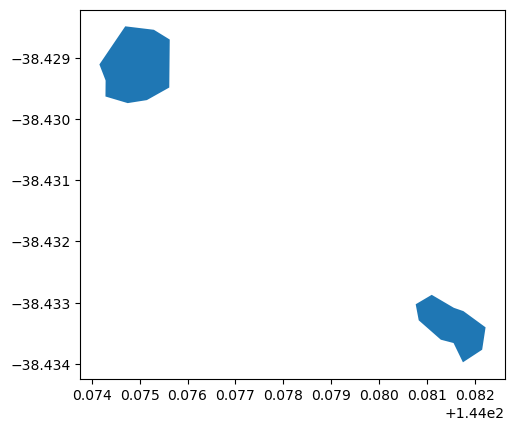

In [197]:
process_file['geometry'].loc[process_file['NAME']=='Aireys Inlet - Distillery Creek'].loc[[514136,636702]].plot()

In [30]:
SD = pd.to_datetime(process_file['START_DATE'],format='%Y-%m-%d')
ST = pd.to_datetime(process_file['STRTDATIT'],format='%Y%m%d')

In [35]:
process_file.loc[SD!=ST]

,FIRETYPE,SEASON,FIRE_NO,NAME,START_DATE,STRTDATIT,TREAT_TYPE,FIRE_SVRTY,FIRE_COVER,FIREKEY,CR_DATE,UPDATEDATE,AREA_HA,METHOD,METHD_CMNT,ACCURACY,DSE_ID,CFA_ID,DISTRICTID,geometry
376,BURN,2021,BSW-OTW-GEL-0032,Gellibrand - Boggy Creek Track,2021-05-31,20210503,ECOLOGICAL,BURNT_3,90-100,3007133,2021-06-09,None,0.290024,Aerial Photograph Interpretation,Primarily used colour IR,HIGH,0.0,0.0,12,"POLYGON ((143.46428 -38.54806, 143.46429 -38.5..."
2810,BURN,2020,BSW-FSW-CST-0011,BAHGALLAH SF - GLENELG RIVER - NORTHERN BLOCK,2020-04-14,20200415,FUEL REDUCTION,BURNT_2P,50-69,B20201411,2020-04-14,2020-11-25,0.333677,Aerial Photograph Interpretation,Aerial photography post burn analysis,HIGH,817912.0,NaN,14,"POLYGON ((141.32135 -37.64806, 141.32136 -37.6..."
2891,BURN,2015,2OCR0120,Cann River - Bralak Road,2015-03-11,20130311,ECOLOGICAL,BURNT_2P,90-100,B2015452OCR0120,2015-06-09,None,745.088024,Aerial Photograph Interpretation,15cm_CIR_VIS,HIGH,838921.0,NaN,45,"MULTIPOLYGON (((149.53352 -37.63758, 149.53334..."
5407,BURN,2015,2OOR0013,Bemm River - Pighole Tk A,2015-04-01,20140401,FUEL REDUCTION,BURNT_3,90-100,B2015452OOR0013,2015-06-30,None,0.044683,Aerial Photograph Interpretation,15cm_CIR_VIS,HIGH,599702.0,NaN,45,"POLYGON ((148.94730 -37.73305, 148.94738 -37.7..."
5960,BURN,2016,2BER0023,TANJIL - TANJIL JUNCTION EAST,2016-04-26,20160326,FUEL REDUCTION,BURNT_3,90-100,B2016472BER0023,2016-07-25,None,259.663770,Aerial Photograph Interpretation,15cm_CIR_VIS,HIGH,819866.0,NaN,47,"MULTIPOLYGON (((146.19458 -37.97874, 146.19433..."
9878,BURN,2021,GR-MID-BAL-0061,SMYTHESDALE - TILLIGS ROAD,2021-06-06,20210306,FUEL REDUCTION,BURNT_2P,UNKNOWN,B202115GR-MID-BAL-0061,2021-03-09,None,194.126746,Aerial Photograph Interpretation,None,UNKNOWN,NaN,NaN,15,"POLYGON ((143.69204 -37.68832, 143.69183 -37.6..."
12504,BURN,2020,BSW-FSW-HEW-0037,GORAE - PORTLAND - NELSON RD BLOCK 3,2020-03-09,20200310,FUEL REDUCTION,BURNT_2F,90-100,B20201437,2020-03-09,2020-11-25,1.068980,Aerial Photograph Interpretation,None,HIGH,868932.0,NaN,14,"POLYGON ((141.54806 -38.26953, 141.54775 -38.2..."
13327,BURN,1981,None,PYRETE RANGE BURN,1980-09-25,19810101,None,BURNT_UNKNOWN,0-9,None,None,1899-12-30,158.348228,None,None,MEDIUM,0.0,0.0,15,"POLYGON ((144.54687 -37.53515, 144.54710 -37.5..."
13560,BURN,2015,2OOR0101,Monorina - Princes Highway,2015-03-13,20130313,FUEL REDUCTION,BURNT_2F,90-100,B2015452OOR0101,2015-06-11,None,269.255094,Aerial Photograph Interpretation,15cm_CIR_VIS,HIGH,753531.0,NaN,45,"POLYGON ((148.76376 -37.68989, 148.76368 -37.6..."
20959,BURN,2021,BSW-OTW-ANG-0049,Moggs Creek - Forest Drive,2021-04-30,20210429,FUEL REDUCTION,BURNT_2F,70-89,876841,2021-09-10,2021-10-05,40.053660,Aerial Photograph Interpretation,Primarily used colour IR.,MEDIUM,NaN,NaN,12,"POLYGON ((144.07347 -38.46377, 144.07325 -38.4..."


In [14]:
process_file.loc[process_file['NAME']=='Anglesea - Salt Creek','FIRE_NO'] = 

In [39]:
process_file.loc[process_file['NAME']=='Kentbruck - Kentbruck Heath']

,FIRETYPE,SEASON,FIRE_NO,NAME,START_DATE,STRTDATIT,TREAT_TYPE,FIRE_SVRTY,FIRE_COVER,FIREKEY,CR_DATE,UPDATEDATE,AREA_HA,METHOD,METHD_CMNT,ACCURACY,DSE_ID,CFA_ID,DISTRICTID,geometry
390200,BURN,2022,BSW-FSW-PTD-0024,Kentbruck - Kentbruck Heath,2021-08-10,20210810,FUEL REDUCTION,BURNT_UNKNOWN,UNKNOWN,B202214BSW-FSW-PTD-0024,None,None,1.960392,None,None,UNKNOWN,3007042.0,NaN,14,"POLYGON ((141.29725 -38.15592, 141.29754 -38.1..."
668173,BURN,2021,BSW-FSW-PTD-0024,Kentbruck - Kentbruck Heath,2021-08-10,20210810,ECOLOGICAL,BURNT_NONFOREST,90-100,3007042,2021-08-10,2021-08-19,8.857165,Aerial Photograph Interpretation,Discussion with FSW FMT,HIGH,NaN,NaN,14,"POLYGON ((141.31284 -38.12935, 141.31311 -38.1..."
723875,BURN,2023,BSW-FSW-PTD-0024,Kentbruck - Kentbruck Heath,2022-07-30,20220730,ECOLOGICAL,BURNT_3,50-69,B202314BSW-FSW-PTD-0024,2023-06-08,None,26.521255,Ground Observer - GPS,Onground Observation,HIGH,3007042.0,NaN,14,"POLYGON ((141.30595 -38.12673, 141.30649 -38.1..."


In [16]:
for i in process_file.groupby(['NAME']).size()[process_file.groupby(['NAME']).size()>1].index:
    dup_idx = process_file.loc[process_file['NAME']==i].duplicated(subset=['STRTDATIT'],keep=False)
    if dup_idx.all():
        continue
    print(process_file[['NAME','START_DATE','STRTDATIT','FIRE_NO','AREA_HA','METHOD']].loc[process_file['NAME']==i].loc[dup_idx])

Empty DataFrame
Columns: [NAME, START_DATE, STRTDATIT, FIRE_NO, AREA_HA, METHOD]
Index: []
Empty DataFrame
Columns: [NAME, START_DATE, STRTDATIT, FIRE_NO, AREA_HA, METHOD]
Index: []
Empty DataFrame
Columns: [NAME, START_DATE, STRTDATIT, FIRE_NO, AREA_HA, METHOD]
Index: []
Empty DataFrame
Columns: [NAME, START_DATE, STRTDATIT, FIRE_NO, AREA_HA, METHOD]
Index: []
Empty DataFrame
Columns: [NAME, START_DATE, STRTDATIT, FIRE_NO, AREA_HA, METHOD]
Index: []
Empty DataFrame
Columns: [NAME, START_DATE, STRTDATIT, FIRE_NO, AREA_HA, METHOD]
Index: []
Empty DataFrame
Columns: [NAME, START_DATE, STRTDATIT, FIRE_NO, AREA_HA, METHOD]
Index: []
Empty DataFrame
Columns: [NAME, START_DATE, STRTDATIT, FIRE_NO, AREA_HA, METHOD]
Index: []
Empty DataFrame
Columns: [NAME, START_DATE, STRTDATIT, FIRE_NO, AREA_HA, METHOD]
Index: []
Empty DataFrame
Columns: [NAME, START_DATE, STRTDATIT, FIRE_NO, AREA_HA, METHOD]
Index: []
                                   NAME  START_DATE  STRTDATIT  FIRE_NO  \
514136  Aireys 

Empty DataFrame
Columns: [NAME, START_DATE, STRTDATIT, FIRE_NO, AREA_HA, METHOD]
Index: []
Empty DataFrame
Columns: [NAME, START_DATE, STRTDATIT, FIRE_NO, AREA_HA, METHOD]
Index: []
Empty DataFrame
Columns: [NAME, START_DATE, STRTDATIT, FIRE_NO, AREA_HA, METHOD]
Index: []
Empty DataFrame
Columns: [NAME, START_DATE, STRTDATIT, FIRE_NO, AREA_HA, METHOD]
Index: []
                                    NAME  START_DATE  STRTDATIT   FIRE_NO  \
98517   Clifton Creek - Blacks Camp Road  2013-04-27   20130427  2BBB0004   
148757  Clifton Creek - Blacks Camp Road  2013-04-27   20130427  2BBB0004   

         AREA_HA                                      METHOD  
98517   0.688460            Aerial Photograph Interpretation  
148757  0.688462  Aerial Photograph Interpretation - Unknown  
Empty DataFrame
Columns: [NAME, START_DATE, STRTDATIT, FIRE_NO, AREA_HA, METHOD]
Index: []
Empty DataFrame
Columns: [NAME, START_DATE, STRTDATIT, FIRE_NO, AREA_HA, METHOD]
Index: []
Empty DataFrame
Columns: [NAME, S

Empty DataFrame
Columns: [NAME, START_DATE, STRTDATIT, FIRE_NO, AREA_HA, METHOD]
Index: []
Empty DataFrame
Columns: [NAME, START_DATE, STRTDATIT, FIRE_NO, AREA_HA, METHOD]
Index: []
Empty DataFrame
Columns: [NAME, START_DATE, STRTDATIT, FIRE_NO, AREA_HA, METHOD]
Index: []
Empty DataFrame
Columns: [NAME, START_DATE, STRTDATIT, FIRE_NO, AREA_HA, METHOD]
Index: []
Empty DataFrame
Columns: [NAME, START_DATE, STRTDATIT, FIRE_NO, AREA_HA, METHOD]
Index: []
Empty DataFrame
Columns: [NAME, START_DATE, STRTDATIT, FIRE_NO, AREA_HA, METHOD]
Index: []
Empty DataFrame
Columns: [NAME, START_DATE, STRTDATIT, FIRE_NO, AREA_HA, METHOD]
Index: []
Empty DataFrame
Columns: [NAME, START_DATE, STRTDATIT, FIRE_NO, AREA_HA, METHOD]
Index: []
Empty DataFrame
Columns: [NAME, START_DATE, STRTDATIT, FIRE_NO, AREA_HA, METHOD]
Index: []
Empty DataFrame
Columns: [NAME, START_DATE, STRTDATIT, FIRE_NO, AREA_HA, METHOD]
Index: []
Empty DataFrame
Columns: [NAME, START_DATE, STRTDATIT, FIRE_NO, AREA_HA, METHOD]
Index: []

Empty DataFrame
Columns: [NAME, START_DATE, STRTDATIT, FIRE_NO, AREA_HA, METHOD]
Index: []
Empty DataFrame
Columns: [NAME, START_DATE, STRTDATIT, FIRE_NO, AREA_HA, METHOD]
Index: []
Empty DataFrame
Columns: [NAME, START_DATE, STRTDATIT, FIRE_NO, AREA_HA, METHOD]
Index: []
Empty DataFrame
Columns: [NAME, START_DATE, STRTDATIT, FIRE_NO, AREA_HA, METHOD]
Index: []
Empty DataFrame
Columns: [NAME, START_DATE, STRTDATIT, FIRE_NO, AREA_HA, METHOD]
Index: []
Empty DataFrame
Columns: [NAME, START_DATE, STRTDATIT, FIRE_NO, AREA_HA, METHOD]
Index: []
Empty DataFrame
Columns: [NAME, START_DATE, STRTDATIT, FIRE_NO, AREA_HA, METHOD]
Index: []
Empty DataFrame
Columns: [NAME, START_DATE, STRTDATIT, FIRE_NO, AREA_HA, METHOD]
Index: []
Empty DataFrame
Columns: [NAME, START_DATE, STRTDATIT, FIRE_NO, AREA_HA, METHOD]
Index: []
Empty DataFrame
Columns: [NAME, START_DATE, STRTDATIT, FIRE_NO, AREA_HA, METHOD]
Index: []
Empty DataFrame
Columns: [NAME, START_DATE, STRTDATIT, FIRE_NO, AREA_HA, METHOD]
Index: []

In [12]:
# Get rid of duplicates; checks that all column parameters are the same minus geometry, NAME, AREA_HA, UPDATEDATE,
# FIRE_SVRTY, and FIRE_COVER, FIREKEY, METHOD, METHD_CMNT, CR_DATE, ACCURACY, DSE_ID, CFA_ID, DISTRICTID
# (since these can differ and still refer to the same burn)
process_file = raw_file.copy()
process_file.drop_duplicates(subset=['FIRETYPE','SEASON','FIRE_NO','NAME','START_DATE','STRTDATIT','TREAT_TYPE'],inplace=True)

multi_burns_name = raw_file.groupby(['NAME']).size()[raw_file.groupby(['NAME']).size()>1].index
skipped_names = []
for name in multi_burns_name:
    # Check if all other columns are the same; e.g., if multiple burns of same NAME, check they are actually different
    if len(process_file[process_file['NAME']==name])>1:
        skipped_names.append(name)
        continue
    # Get sum of areas of all polygons
    sum_area = raw_file[raw_file['NAME']==name]['AREA_HA'].sum()
    # Set area column of all burn duplicates equal to the sum of all polygons (duplicates will be removed at the end)
    raw_file.loc[raw_file['NAME']==name,'AREA_HA'] = sum_area
    # Create multipolygon
    poly_combine = shply.ops.unary_union(raw_file[raw_file['NAME']==name]['geometry'])
    process_file.loc[process_file['NAME']==name] = process_file.loc[process_file['NAME']==name].set_geometry([poly_combine],crs=raw_file.crs)

In [92]:
raw_file[raw_file['NAME']=='06.G17 Henty Hwy'].drop_duplicates(subset=['FIRETYPE','SEASON','FIRE_NO',
                                                                        'NAME','START_DATE','STRTDATIT',
                                                                        'TREAT_TYPE','FIRE_SVRTY','FIRE_COVER',
                                                                        'FIREKEY','CR_DATE','UPDATEDATE','METHOD',
                                                                       'METHD_CMNT','ACCURACY','DSE_ID','CFA_ID','DISTRICTID'])

,FIRETYPE,SEASON,FIRE_NO,NAME,START_DATE,STRTDATIT,TREAT_TYPE,FIRE_SVRTY,FIRE_COVER,FIREKEY,CR_DATE,UPDATEDATE,AREA_HA,METHOD,METHD_CMNT,ACCURACY,DSE_ID,CFA_ID,DISTRICTID,geometry
23679,BURN,2009,06.G17,06.G17 Henty Hwy,2009-05-06,20090506,ECOLOGICAL,BURNT_2,50-69,None,None,None,0.003075,Unknown,None,UNKNOWN,NaN,NaN,None,"POLYGON ((142.21213 -37.26450, 142.21215 -37.2..."


In [123]:
process_file = raw_file.copy()
process_file.drop_duplicates(subset=['FIRETYPE','SEASON','FIRE_NO','NAME','START_DATE','STRTDATIT',
                                    'TREAT_TYPE','FIRE_SVRTY','FIRE_COVER','FIREKEY','CR_DATE','UPDATEDATE',
                                     'METHOD','METHD_CMNT','ACCURACY','DSE_ID','CFA_ID','DISTRICTID'],inplace=True)

name=multi_burns_name[0]
# Get sum of areas of all polygons
sum_area = raw_file[raw_file['NAME']==name]['AREA_HA'].sum()
# Set area column of all burn duplicates equal to the sum of all polygons (duplicates will be removed at the end)
raw_file.loc[raw_file['NAME']==name,'AREA_HA'] = sum_area
# Create multipolygon
poly_combine = shply.ops.unary_union(raw_file[raw_file['NAME']==name]['geometry'])
process_file.loc[process_file['NAME']==name] = process_file.loc[process_file['NAME']==name].set_geometry([poly_combine],crs=raw_file.crs)

In [147]:
process_file.loc[process_file['NAME']==name] = process_file.loc[process_file['NAME']==name].set_geometry([poly_combine],crs=raw_file.crs)

In [152]:
process_file.loc[process_file['NAME']==name]

,FIRETYPE,SEASON,FIRE_NO,NAME,START_DATE,STRTDATIT,TREAT_TYPE,FIRE_SVRTY,FIRE_COVER,FIREKEY,CR_DATE,UPDATEDATE,AREA_HA,METHOD,METHD_CMNT,ACCURACY,DSE_ID,CFA_ID,DISTRICTID,geometry
420572,BURN,2015,99,143 GILLAN RD BELGRAVE SOUTH,2014-12-03,20141203,FUEL REDUCTION,BURNT_3,90-100,None,None,None,14.380648,Aerial Photograph Interpretation - Unknown,None,MEDIUM,NaN,NaN,None,"POLYGON ((145.37158 -37.93860, 145.37128 -37.9..."
715602,BURN,2016,1315018,143 GILLAN RD BELGRAVE SOUTH,2016-04-03,20160403,FUEL REDUCTION,BURNT_2,90-100,None,None,None,14.380648,Unknown,"Ground Truthing, GPS",HIGH,NaN,1315018.0,None,"POLYGON ((145.37165 -37.94028, 145.37157 -37.9..."


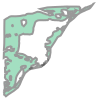

In [124]:
process_file.loc[process_file['NAME']==name].set_geometry([poly_combine],crs=raw_file.crs)

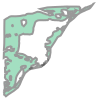

In [41]:
# 
shply.ops.unary_union(raw_file[raw_file['NAME']=='06.G17 Henty Hwy']['geometry'])

In [3]:
# Read in specific rows - use to view what columns of data there are
def gpd_rows(filename, List):
    List = sorted(List) # if the elements of the list are not sorted
    with fiona.open(filename) as source:
        for i, feature in enumerate(source[:max(List)+1]):
            if i in List:
                yield feature
                
# Read in specific columns - extract all columns needed for CSV
def gpd_cols(filename, usecols, **kwargs):
    with fiona.open(filename, **kwargs) as source:
        for feature in source:
            f = {k: feature[k] for k in ['id', 'geometry']}
            f['properties'] = {k: feature['properties'][k] for k in usecols}
            yield f
                
row = gpd.GeoDataFrame.from_features(gpd_rows(file_name,[0]))

/gpfs/home/zna22eeu/.conda/envs/geo_env/lib/python3.8/site-packages/fiona/collection.py:331: FionaDeprecationWarning: Collection slicing is deprecated and will be disabled in a future version.
  return self.session.__getitem__(item)


In [1]:
# Extract FIRETYPE column to get indices of Rx fires
FIRETYPE = gpd.GeoDataFrame.from_features(gpd_cols(file_name,['FIRETYPE']))

# Get indices of Rx fires
Rx_idx = FIRETYPE.index[FIRETYPE['FIRETYPE']=='BURN']

del FIRETYPE

# Extract other features needed for CSV
features = gpd.GeoDataFrame.from_features(gpd_cols(file_name,['START_DATE','TREAT_TYPE','AREA_HA']))
features = features.loc[Rx_idx]

NameError: name 'gpd' is not defined

In [18]:
# Lat, lon, date - in steps or else kernel dies, idk
Rx_lon = features['geometry'].centroid.x.values
Rx_lat = features['geometry'].centroid.y.values

Rx_date = features['START_DATE']

In [19]:
# Create dataframe
cols = ['Raw data filename(s)','ID','Latitude','Longitude','Year','Month','Day','Time','Fire Type',
        'Country','State/Province','Agency / Organisation','Timestamp of Update','Link to Data Repository',
        'Citation','Area Burned','Area Burned Units']

# Prefill dataframe with None
df = pd.DataFrame(columns=cols,data=np.full((len(Rx_idx),len(cols)),None))

# Fill dataset - distinct values per row
df['Longitude'] = Rx_lon
df['Latitude'] = Rx_lat

df['Year'] = pd.to_datetime(features['START_DATE'].values).year
df['Month'] = pd.to_datetime(features['START_DATE'].values).month
df['Day'] = pd.to_datetime(features['START_DATE'].values).day

df['Area Burned'] = features['AREA_HA'].values
df['Fire Type'] = features['TREAT_TYPE'].values

In [24]:
# Fill dataset - same values for every row
df['Raw data filename(s)'] = file_name.split('/')[-1]
df['ID'] = np.array(['DELWP'+str(i) for i in features.index])
df['Country'] = 'Australia'
df['State/Province'] = 'Victoria'
df['Agency / Organisation'] = 'Department of Environment, Land, Water & Planning;Department of Energy, Environment and Climate Action'
df['Timestamp of Update'] = pd.Timestamp.today()
df['Link to Data Repository'] = 'https://datashare.maps.vic.gov.au/search?q=uuid%3Dd817f3be-a7a2-5847-9944-c0f2fdb39444'
df['Citation'] = 'Department of Environment, Land, Water & Planning 2023'
df['Area Burned Units'] = 'Ha'

In [44]:
# Get rid of all rows where no date is recorded
df = df[Rx_date.values!=None]

# Save to CSV
df.to_csv('Process_Rx/Australia/Victoria.csv')

## Western Australia
* Lookup table for dataset [here](https://catalogue.data.wa.gov.au/dataset/dbca-fire-history/resource/086c43d0-3e00-45a2-9161-c0e9f4700830)
* GDA94
* This section needs to be run as an `sbatch` job

In [3]:
region = 'Western_Australia'
file_name = glob.glob('Raw_Rx/Australia/'+region+'/*.shp')[0]

In [6]:
# Read in specific rows - use to view what columns of data there are
def gpd_rows(filename, List):
    List = sorted(List) # if the elements of the list are not sorted
    with fiona.open(filename) as source:
        for i, feature in enumerate(source[:max(List)+1]):
            if i in List:
                yield feature
                
# Read in specific columns - extract all columns needed for CSV
def gpd_cols(filename, usecols, **kwargs):
    with fiona.open(filename, **kwargs) as source:
        for feature in source:
            f = {k: feature[k] for k in ['id', 'geometry']}
            f['properties'] = {k: feature['properties'][k] for k in usecols}
            yield f
                
rows = gpd.GeoDataFrame.from_features(gpd_rows(file_name,[0]))
rows

/gpfs/home/zna22eeu/.conda/envs/geo_env/lib/python3.8/site-packages/fiona/collection.py:331: FionaDeprecationWarning: Collection slicing is deprecated and will be disabled in a future version.
  return self.session.__getitem__(item)


,geometry,fih_fire_s,fih_year1,fih_season,fih_distri,fih_hist_d,fih_number,fih_fire_t,fih_date1,fih_cause,...,fih_author,fih_poly_t,fih_commen,fih_name,fih_burn_p,fih_master,fih_perime,fih_hectar,st_area_sh,st_perimet
0,"POLYGON ((116.07430 -31.94556, 116.07434 -31.9...",1937/1938,1938,SU,PHL,Mundaring,999,WF,1938-01-01,999,...,None,Actual Burnt,Wildfire,None,0,43952,6.288631,174.906766,0.000167,0.060722


In [7]:
# Extract fih_fire_t column to get indices of Rx fires
fire_t = gpd.GeoDataFrame.from_features(gpd_cols(file_name,['fih_fire_t']))

# Get indices of Rx fires
Rx_idx = fire_t.index[fire_t['fih_fire_t']=='PB']

del fire_t

In [ ]:
# Extract other features needed for CSV
features = gpd.GeoDataFrame.from_features(gpd_cols(file_name,['fih_date1','fih_burn_p','fih_hectar']))
features = features.loc[Rx_idx]

In [ ]:
Rx_lon = features['geometry'].centroid.x.values
Rx_lat = features['geometry'].centroid.y.values

Rx_date = features['fih_date1']

In [ ]:
# Create dataframe
cols = ['Raw data filename(s)','ID','Latitude','Longitude','Year','Month','Day','Time','Fire Type',
        'Country','State/Province','Agency / Organisation','Timestamp of Update','Link to Data Repository',
        'Citation','Area Burned','Area Burned Units']

# Prefill dataframe with None
df = pd.DataFrame(columns=cols,data=np.full((len(Rx_idx),len(cols)),None))

# Fill dataset - distinct values per row
df['Longitude'] = Rx_lon
df['Latitude'] = Rx_lat

df['Year'] = pd.to_datetime(features['fih_date1'].values).year
df['Month'] = pd.to_datetime(features['fih_date1'].values).month
df['Day'] = pd.to_datetime(features['fih_date1'].values).day

df['Area Burned'] = features['fih_hectar'].values
df['Fire Type'] = features['fih_burn_p'].values

In [ ]:
# Fill dataset - same values for every row
df['Raw data filename(s)'] = file_name.split('/')[-1]
df['ID'] = np.array(['DBCA'+str(i) for i in features.index])
df['Country'] = 'Australia'
df['State/Province'] = 'Western Australia'
df['Agency / Organisation'] = 'Government of Western Australia Department of Biodiversity, Conservation and Attractions (WA-DBCA)'
df['Timestamp of Update'] = pd.Timestamp.today()
df['Link to Data Repository'] = 'https://datashare.maps.vic.gov.au/search?q=uuid%3Dd817f3be-a7a2-5847-9944-c0f2fdb39444'
df['Citation'] = 'WA-DBCA 2023'
df['Area Burned Units'] = 'Ha'

In [ ]:
# Get rid of all rows where no date is recorded
df = df[Rx_date.values!=None]

# Save to CSV
df.to_csv('Process_Rx/Australia/Western_Australia.csv')

## New South Wales
* Metadata for dataset [here](https://datasets.seed.nsw.gov.au/dataset/fire-history-wildfires-and-prescribed-burns-1e8b6/metaexport/iso19115_pdf)
    * Some information in metadata is inconsistent with dataset
* GDA94

In [8]:
region = 'New_South_Wales'
file_name = glob.glob('Raw_Rx/Australia/'+region+'/*.shp')[0]

In [67]:
# Read in specific rows - use to view what columns of data there are
def gpd_rows(filename, List):
    List = sorted(List) # if the elements of the list are not sorted
    with fiona.open(filename) as source:
        for i, feature in enumerate(source[:max(List)+1]):
            if i in List:
                yield feature
                
# Read in specific columns - extract all columns needed for CSV
def gpd_cols(filename, usecols, **kwargs):
    with fiona.open(filename, **kwargs) as source:
        for feature in source:
            f = {k: feature[k] for k in ['id', 'geometry']}
            f['properties'] = {k: feature['properties'][k] for k in usecols}
            yield f
                
rows = gpd.GeoDataFrame.from_features(gpd_rows(file_name,[0]))
rows

In [53]:
fire_t = gpd.GeoDataFrame.from_features(gpd_cols(file_name,['FireType']))
Rx_idx = fire_t.index[fire_t['FireType']==2]

features = gpd.GeoDataFrame.from_features(gpd_cols(file_name,['StartDate','AreaHa']))
features = features.loc[Rx_idx]

In [57]:
Rx_lon = features['geometry'].centroid.x.values
Rx_lat = features['geometry'].centroid.y.values

Rx_date = features['StartDate']

In [60]:
# Create dataframe
cols = ['Raw data filename(s)','ID','Latitude','Longitude','Year','Month','Day','Time','Fire Type',
        'Country','State/Province','Agency / Organisation','Timestamp of Update','Link to Data Repository',
        'Citation','Area Burned','Area Burned Units']

# Prefill dataframe with None
df = pd.DataFrame(columns=cols,data=np.full((len(Rx_idx),len(cols)),None))

# Fill dataset - distinct values per row
df['Longitude'] = Rx_lon
df['Latitude'] = Rx_lat

df['Year'] = pd.to_datetime(Rx_date.values).year
df['Month'] = pd.to_datetime(Rx_date.values).month
df['Day'] = pd.to_datetime(Rx_date.values).day

df['Area Burned'] = features['AreaHa'].values
df['ID'] = np.array(['NPWS'+str(i) for i in features.index])

In [61]:
# Fill dataset - same values for every row
df['Raw data filename(s)'] = file_name.split('/')[-1]
df['Country'] = 'Australia'
df['State/Province'] = 'New South Wales'
df['Agency / Organisation'] = 'New South Wales Department of Planning, Industry and Environment (NSW-NPWS)'
df['Timestamp of Update'] = pd.Timestamp.today()
df['Link to Data Repository'] = 'https://datasets.seed.nsw.gov.au/dataset/fire-history-wildfires-and-prescribed-burns-1e8b6'
df['Citation'] = 'State Government of NSW and Department of Planning and Environment 2010'
df['Area Burned Units'] = 'Ha'
df['Fire Type'] = 'Prescribed Burn'

In [66]:
# Get rid of all rows where no date is recorded
df = df[Rx_date.values!=None]

# Save to CSV
df.to_csv('Process_Rx/Australia/New_South_Wales.csv')

## South Australia
* Link to [metadata](https://location.sa.gov.au/LMS/Reports/ReportMetadata.aspx?p_no=1159&pu=y&pa=dewnr)
* both GDA94 and GDA20 available, using GDA94 to preserve consistency among other states

In [76]:
region = 'South_Australia'
file_name = glob.glob('Raw_Rx/Australia/'+region+'/*94.shp')[0]
fire_df = gpd.read_file(file_name)

In [90]:
# Extract planned fires from dataset and export
fire_df.groupby('INCIDENTTY').size()
Rx_df = fire_df[fire_df['INCIDENTTY']=='Prescribed Burn']
Rx_df = Rx_df.to_crs('EPSG:4326')

# Find centroid of burned area; need to convert to flat projection to find centroid, then convert back to EPSG
# Get Latitude and Longitude
Rx_centroids = Rx_df['geometry'].to_crs('+proj=cea').centroid.to_crs('EPSG:4326')
Rx_lon = Rx_centroids.x.values
Rx_lat = Rx_centroids.y.values

# Get dates of Rx burns
Rx_dates = pd.to_datetime(Rx_df['FIREDATE'].values)
Rx_year = Rx_dates.year
Rx_month = Rx_dates.month
Rx_day = Rx_dates.day

# Get Area Burned anad convert to Ha
Rx_BA = Rx_df['HECTARES'].values

# Create burn ID
Rx_ID = Rx_df['INCIDENTNU']

In [91]:
# Assign data to DataFrame

cols = ['Raw data filename(s)','ID','Latitude','Longitude','Year','Month','Day','Time','Fire Type',
        'Country','State/Province','Agency / Organisation','Timestamp of Update','Link to Data Repository',
        'Citation','Area Burned','Area Burned Units']
df = pd.DataFrame(columns=cols)

df['ID'] = Rx_ID
df['Latitude'] = Rx_lat
df['Longitude'] = Rx_lon
df['Year'] = Rx_year
df['Month'] = Rx_month
df['Day'] = Rx_day
df['Fire Type'] = 'Prescribed'
df['Country'] = 'Australia'
df['State/Province'] = 'South Australia'
df['Agency / Organisation'] = 'Department for Environment and Water'
df['Timestamp of Update'] = pd.Timestamp.today().date()
df['Link to Data Repository'] = 'https://data.sa.gov.au/data/dataset/fire-history'
df['Citation'] = 'Government of South Australia Department for Environment and Water (SA-DEW). Fire history, https://data.sa.gov.au/data/dataset/fire-history (2024)'
df['Area Burned'] = Rx_BA
df['Area Burned Units'] = 'Ha'

df['Raw data filename(s)'] = file_name.split('/')[-1]

# Get rid of all rows where no date is recorded
df = df[Rx_dates.values!=None]

# Save to CSV
df.to_csv('Process_Rx/Australia/South_Australia.csv')

## Queensland
* Metadata [here](https://qldspatial.information.qld.gov.au/catalogue/custom/viewMetadataDetails.page?uuid=%7B607736AE-8F4C-4058-B97F-CF617413EC3E%7D)
* GDA94

In [116]:
region = 'Queensland'
file_name = glob.glob('Raw_Rx/Australia/'+region+'/*.shp')[0]

fire_df = gpd.read_file(file_name)

In [119]:
# Extract planned fires from dataset and export
fire_df.groupby('TYPE').size()
Rx_df = fire_df[fire_df['TYPE']=='PB']
Rx_df = Rx_df.to_crs('EPSG:4326')

# Find centroid of burned area; need to convert to flat projection to find centroid, then convert back to EPSG
# Get Latitude and Longitude
Rx_centroids = Rx_df['geometry'].to_crs('+proj=cea').centroid.to_crs('EPSG:4326')
Rx_lon = Rx_centroids.x.values
Rx_lat = Rx_centroids.y.values

# Get dates of Rx burns
Rx_dates = pd.to_datetime(Rx_df['IGNITIONDA'].values)
Rx_year = Rx_dates.year
Rx_month = Rx_dates.month
Rx_day = Rx_dates.day

# Get Area Burned anad convert to Ha
Rx_BA = Rx_df['AREA_HA'].values

# Create burn ID
Rx_ID = Rx_df.index

In [120]:
# Assign data to DataFrame
cols = ['Raw data filename(s)','ID','Latitude','Longitude','Year','Month','Day','Time','Fire Type',
        'Country','State/Province','Agency / Organisation','Timestamp of Update','Link to Data Repository',
        'Citation','Area Burned','Area Burned Units']
df = pd.DataFrame(columns=cols)

df['ID'] = Rx_ID
df['Latitude'] = Rx_lat
df['Longitude'] = Rx_lon
df['Year'] = Rx_year
df['Month'] = Rx_month
df['Day'] = Rx_day
df['Fire Type'] = 'Prescribed'
df['Country'] = 'Australia'
df['State/Province'] = 'Queensland'
df['Agency / Organisation'] = 'Queensland Parks and Wildlife Service'
df['Timestamp of Update'] = pd.Timestamp.today().date()
df['Link to Data Repository'] = 'https://www.data.qld.gov.au/dataset/fire-history-queensland-parks-and-wildlife-service/resource/92c713c7-c6ef-47c2-bd5d-63884f1dc1d0'
df['Citation'] = 'State of Queensland (Department of Environment and Science) 2023'
df['Area Burned'] = Rx_BA
df['Area Burned Units'] = 'Ha'

df['Raw data filename(s)'] = file_name.split('/')[-1]

# Get rid of all rows where no date is recorded
df = df[Rx_dates.values!=None]

# Save to CSV
df.to_csv('Process_Rx/Australia/Queensland.csv')

# USA

## FTM Database
* Metadata [here](https://www.fs.usda.gov/rds/archive/products/RDS-2020-0001-2/_metadata_RDS-2020-0001-2.html)

In [143]:
file_name = glob.glob('Raw_Rx/USA/FTM/FTM_fires.csv')[0]

In [144]:
fire_df = pd.read_csv(file_name)
Rx_df = fire_df[(fire_df['Fire_type']=='RX')+(fire_df['Fire_type']=='Rx')]
Rx_df = Rx_df[~np.isnan(Rx_df['yr_fire']+Rx_df['month_fire']+Rx_df['day_fire']).values]
Rx_df.drop_duplicates(subset=['yr_fire','month_fire','day_fire','Latitude','Longitude'],inplace=True)

In [171]:
Rx_df.loc[Rx_df['Plot_size_ha']=='0.06; three 0.2 ha subplots']

,YrFireName,Fire,Dataset,N,yr_fire,Latitude,Longitude,Elevation,month_fire,day_fire,Fire_type,State,Sample_design,Plot_size_ha,Threshold_diameter_cm,Study_purpose
183,2002 - Crater-FB-B,Crater-FB-B,Perrakis,32,2002,42.802901,-122.08235,1480,10.0,10.0,RX,Oregon,Fixed-area plot,0.06; three 0.2 ha subplots,5,Fuel Treatment Effects; Tree Mortality
185,2002 - Crater-FB-J,Crater-FB-J,Perrakis,118,2002,42.802901,-122.08235,1480,10.0,9.0,RX,Oregon,Fixed-area plot,0.06; three 0.2 ha subplots,5,Fuel Treatment Effects; Tree Mortality
191,2002 - Crater-SB-A,Crater-SB-A,Perrakis,104,2002,42.802901,-122.08235,1480,6.0,22.0,RX,Oregon,Fixed-area plot,0.06; three 0.2 ha subplots,5,Fuel Treatment Effects; Tree Mortality
193,2002 - Crater-SB-E,Crater-SB-E,Perrakis,128,2002,42.802901,-122.08235,1480,6.0,28.0,RX,Oregon,Fixed-area plot,0.06; three 0.2 ha subplots,5,Fuel Treatment Effects; Tree Mortality
197,2002 - Crater-SB-V,Crater-SB-V,Perrakis,63,2002,42.802901,-122.08235,1480,6.0,21.0,RX,Oregon,Fixed-area plot,0.06; three 0.2 ha subplots,5,Fuel Treatment Effects; Tree Mortality
198,2002 - Crater-SB-W,Crater-SB-W,Perrakis,58,2002,42.802901,-122.08235,1480,6.0,20.0,RX,Oregon,Fixed-area plot,0.06; three 0.2 ha subplots,5,Fuel Treatment Effects; Tree Mortality


In [172]:
Rx_df.loc[Rx_df['Plot_size_ha']=='0.06; three 0.2 ha subplots','Plot_size_ha'] = 0.6

In [173]:
for i in Rx_df.groupby(['Plot_size_ha']).size().index:
    print(str(i)+': '+str(Rx_df.groupby(['Plot_size_ha']).size()[i]))

0.00785: 1
0.04: 2
0.0405: 3
0.07: 3
0.0707: 4
0.6: 6
2.125: 2
0.01: 1
0.01815: 2
0.04: 2
0.1: 11
0.125: 1
0.2: 12
1: 4


In [177]:
# Assign data to DataFrame
cols = ['ID','Latitude','Longitude','Year','Month','Day','Time','Burn Objective',
        'Country','State/Province','Agency/Organisation','Timestamp of Update','Data Repository',
        'Citation','Area Burned (Ha)']
df = pd.DataFrame(columns=cols)

df['ID'] = np.array(['FTM'+str(i) for i in Rx_df.index])
df['Latitude'] = Rx_df['Latitude'].values
df['Longitude'] = Rx_df['Longitude'].values
df['Year'] = Rx_df['yr_fire'].values
df['Month'] = Rx_df['month_fire'].values
df['Day'] = Rx_df['day_fire'].values
df['Burn Objective'] = np.array(['Research;'+i for i in Rx_df['Study_purpose']])
df['Country'] = 'USA'
df['State/Province'] = Rx_df['State'].values
df['Agency/Organisation'] = np.array(['Fire and Tree Mortality Database ('+i+')' for i in Rx_df['Dataset']])
df['Timestamp of Update'] = pd.Timestamp.today().date()
df['Data Repository'] = 'https://www.fs.usda.gov/rds/archive/catalog/RDS-2020-0001-2'
df['Citation'] = 'Cansler, C. Alina; Hood, Sharon M.; Varner, J. Morgan; van Mantgem, Phillip J.; Agne, Michelle C.; Andrus, Robert A.; Ayres, Matthew P.; Ayres, Bruce D.; Bakker, Jonathan D.; Battaglia, Michael A.; Bentz, Barbara J.; Breece, Carolyn R.; Brown, James K.; Cluck, Daniel R.; Coleman, Tom W.; Corace, R. Gregory; Covington, W. Wallace; Cram, Douglas S.; Cronan, James B.; Crouse, Joseph E.; Das, Adrian J.; Davis, Ryan S.; Dickinson, Darci M.; Fitzgerald, Stephen A.; Fulé, Peter Z.; Ganio, Lisa M.; Grayson, Lindsay M.; Halpern, Charles B.; Hanula, Jim L.; Harvey, Brian J.; Hiers, J. Kevin; Huffman, David W.; Keifer, MaryBeth; Keyser, Tara L.; Kobziar, Leda N.; Kolb, Thomas E.; Kolden, Crystal A.; Kopper, Karen E.; Kreitler, Jason R.; Kreye, Jesse K.; Latimer, Andrew M.; Lerch, Andrew P.; Lombardero, Maria J.; McDaniel, Virginia L.; McHugh, Charles W.; McMillin, Joel D.; Moghaddas, Jason J.; O’Brien, Joseph J.; Perrakis, Daniel D.B.; Peterson, David W.; Prichard, Susan J.; Progar, Robert A.; Raffa, Kenneth F.; Reinhardt, Elizabeth D.; Restaino, Joseph C.; Roccaforte, John P.; Rogers, Brendan M.; Ryan, Kevin C.; Safford, Hugh D.; Santoro, Alyson E.; Shearman, Timothy M.; Shumate, Alice M.; Sieg, Carolyn H.; Smith, Sheri L.; Smith, Rebecca J.; Stephenson, Nathan L.; Steuver, Mary; Stevens, Jens T.; Stoddard, Michael T.; Thies, Walter G.; Vaillant, Nicole M.; Weiss, Shelby A.; Westlind, Douglas J.; Woolley, Travis J.; Wright, Michah. 2022. Fire and tree mortality database (FTM). 2nd Edition. Fort Collins, CO: Forest Service Research Data Archive. https://doi.org/10.2737/RDS-2020-0001-2'
df['Area Burned (Ha)'] = Rx_df['Plot_size_ha']

# Save to CSV
df.to_csv('Process_Rx/USA/FTM.csv',index=False)

## MTBS
* Metadata link [here](https://www.sciencebase.gov/catalog/file/get/5e541969e4b0ff554f753113?f=__disk__ee%2Fa1%2F6e%2Feea16eb723ba3bfd917a2e1bad8d9509c99302bf&transform=1&allowOpen=true)

In [146]:
file_name = glob.glob('Raw_Rx/USA/MTBS/mtbs_perimeter_data/mtbs_FODpoints_DD.shp')[0]
fire_df = gpd.read_file(file_name)

In [7]:
fire_df.groupby(['Incid_Type']).size()

Incid_Type
Prescribed Fire       8073
Unknown               6303
Wildfire             16040
Wildland Fire Use      211
dtype: int64

In [149]:
Rx_df = fire_df[fire_df['Incid_Type']=='Prescribed Fire'].to_crs('EPSG:4326')
MTBS_Rx = Rx_df

In [51]:
state_dict = {'AK': 'Alaska','AL': 'Alabama','AR': 'Arkansas','AS': 'American Samoa','AZ': 'Arizona',
          'CA': 'California','CO': 'Colorado','CT': 'Connecticut','DC': 'District of Columbia',
          'DE': 'Delaware','FL': 'Florida','GA': 'Georgia','GU': 'Guam','HI': 'Hawaii','IA': 'Iowa',
          'ID': 'Idaho','IL': 'Illinois','IN': 'Indiana','KS': 'Kansas','KY': 'Kentucky','LA': 'Louisiana',
          'MA': 'Massachusetts','MD': 'Maryland','ME': 'Maine','MI': 'Michigan','MN': 'Minnesota',
          'MO': 'Missouri','MP': 'Northern Mariana Islands','MS': 'Mississippi','MT': 'Montana',
          'NA': 'National','NC': 'North Carolina','ND': 'North Dakota','NE': 'Nebraska','NH': 'New Hampshire',
          'NJ': 'New Jersey','NM': 'New Mexico','NV': 'Nevada','NY': 'New York','OH': 'Ohio','OK': 'Oklahoma',
          'OR': 'Oregon','PA': 'Pennsylvania','PR': 'Puerto Rico','RI': 'Rhode Island','SC': 'South Carolina',
          'SD': 'South Dakota','TN': 'Tennessee','TX': 'Texas','UT': 'Utah','VA': 'Virginia','VI': 'Virgin Islands',
          'VT': 'Vermont','WA': 'Washington','WI': 'Wisconsin','WV': 'West Virginia','WY': 'Wyoming'}

In [35]:
# Assign data to DataFrame
cols = ['Raw data filename(s)','ID','Latitude','Longitude','Year','Month','Day','Time','Fire Type',
        'Country','State/Province','Agency / Organisation','Timestamp of Update','Link to Data Repository',
        'Citation','Area Burned','Area Burned Units']
df = pd.DataFrame(columns=cols)

df['ID'] = Rx_df['Event_ID']
df['Latitude'] = Rx_df['geometry'].y.values
df['Longitude'] = Rx_df['geometry'].x.values
df['Year'] = pd.to_datetime(Rx_df['Ig_Date'].values).year
df['Month'] = pd.to_datetime(Rx_df['Ig_Date'].values).month
df['Day'] = pd.to_datetime(Rx_df['Ig_Date'].values).day
df['Fire Type'] = 'Prescribed Fire'
df['Country'] = 'USA'
df['State/Province'] = np.array([state_dict[i[0:2]] for i in Rx_df['Event_ID']])
df['Agency / Organisation'] = 'U.S. Geological Survey;USDA Forest Service'
df['Timestamp of Update'] = pd.Timestamp.today().date()
df['Link to Data Repository'] = 'https://www.sciencebase.gov/catalog/item/5e541969e4b0ff554f753113'
df['Citation'] = 'U.S. Geological Survey, USDA Forest Service, and Nelson, K., 2021, Monitoring Trends in Burn Severity (ver. 7.0, January 2024): U.S. Geological Survey data release, https://doi.org/10.5066/P9IED7RZ'
df['Area Burned'] = Rx_df['BurnBndAc'].values*0.404686
df['Area Burned Units'] = 'Ha'

df['Raw data filename(s)'] = file_name.split('/')[-1]

# Check if any dates are missing
np.isnan(df['Year'].values).any()
np.isnan(df['Month'].values).any()
np.isnan(df['Day'].values).any()

# # Save to CSV
df.to_csv('Process_Rx/USA/MTBS.csv')

## USGS
* Link to metadata [here](https://www.sciencebase.gov/catalog/file/get/61aa537dd34eb622f699df81?f=__disk__d0%2F63%2F53%2Fd063532049be8e1bc83d1d3047b4df1a5cb56f15&transform=1&allowOpen=true)

In [2]:
from shapely.geometry import Point

In [71]:
# Read in USGS shapefile
file_name = glob.glob('Raw_Rx/USA/fire_feature_data_USA.shp')[0]
USGS_raw = gpd.read_file(file_name)

# Drop all data without a date
USGS_raw.dropna(subset=['Rx_Start_D'],inplace=True)

# Filter for years 1979 and after
USGS_raw = USGS_raw.loc[pd.DatetimeIndex(USGS_raw['Rx_Start_D']).year>=1979]

In [4]:
# Read in specific rows - use to view what columns of data there are
def gpd_rows(filename, List):
    List = sorted(List) # if the elements of the list are not sorted
    with fiona.open(filename) as source:
        for i, feature in enumerate(source[:max(List)+1]):
            if i in List:
                yield feature
                
# Read in specific columns - extract all columns needed for CSV
def gpd_cols(filename, usecols, **kwargs):
    with fiona.open(filename, **kwargs) as source:
        for feature in source:
            f = {k: feature[k] for k in ['id', 'geometry']}
            f['properties'] = {k: feature['properties'][k] for k in usecols}
            yield f
                
rows = gpd.GeoDataFrame.from_features(gpd_rows(file_name,range(3,50)))
rows

/gpfs/home/zna22eeu/.conda/envs/geo_env/lib/python3.8/site-packages/fiona/collection.py:331: FionaDeprecationWarning: Collection slicing is deprecated and will be disabled in a future version.
  return self.session.__getitem__(item)


,geometry,OBJECTID,Fire_Tier,Fire_Type,Data_Sourc,Fire_Calen,Fire_Year_,Estimated_,GIS_Acres,GIS_Hectar,...,Rx_Start_D,Rx_End_Dat,Other_Fire,Other_Fi_1,Upload_Dat,Map_Digiti,Data_Notes,Processing,Shape_Leng,Shape_Area
0,"MULTIPOLYGON (((-111.99919 38.41288, -111.9991...",427544.0,6,Prescribed Fire,Comb_National_MTBS,2019,Actual Start Year,None,7850.693253,3177.062841,...,2019/11/18 00:00:00.000,None,None,None,None,MTBS,"Low threshold is very high compared to offset,...",None,87463.182821,3.177063e+07
1,"POLYGON ((-108.09505 33.52268, -108.09505 33.5...",427545.0,6,Prescribed Fire,Comb_National_MTBS,2019,Actual Start Year,None,7815.256766,3162.722204,...,2019/05/31 00:00:00.000,None,None,None,None,MTBS,None,None,66747.809560,3.162722e+07
2,"POLYGON ((-108.00693 33.45002, -108.00695 33.4...",427546.0,6,Prescribed Fire,Comb_National_MTBS,2019,Actual Start Year,None,7263.637645,2939.489865,...,2019/06/30 00:00:00.000,None,None,None,None,MTBS,None,None,31664.292258,2.939490e+07
3,"POLYGON ((-109.36191 33.82181, -109.36190 33.8...",427547.0,6,Prescribed Fire,Comb_National_MTBS,2019,Actual Start Year,None,6335.853359,2564.028886,...,2019/10/21 00:00:00.000,None,None,None,None,MTBS,Scenes separated by 16 days. Fire burned after...,None,37152.041776,2.564029e+07
4,"POLYGON ((-108.42862 33.66280, -108.42861 33.6...",427548.0,6,Prescribed Fire,Comb_National_MTBS,2019,Actual Start Year,None,6305.617967,2551.793057,...,2019/03/07 00:00:00.000,None,None,None,None,MTBS,Area on West side fo fire has low dnbr but is ...,None,24306.848968,2.551793e+07
5,"POLYGON ((-110.53109 32.89464, -110.53110 32.8...",427549.0,6,Prescribed Fire,Comb_National_MTBS,2019,Actual Start Year,None,6092.709268,2465.631963,...,2019/05/31 00:00:00.000,None,None,None,None,MTBS,No high intensity was identified in imagery. ...,None,82041.524505,2.465632e+07
6,"POLYGON ((-120.41868 44.43315, -120.41866 44.4...",427550.0,6,Prescribed Fire,Comb_National_MTBS,2019,Actual Start Year,None,4451.138277,1801.311752,...,2019/09/03 00:00:00.000,None,None,None,None,MTBS,None,None,22779.890369,1.801312e+07
7,"POLYGON ((-118.89425 42.82353, -118.89429 42.8...",427551.0,6,Prescribed Fire,Comb_National_MTBS,2019,Actual Start Year,None,4416.677832,1787.366105,...,2019/03/15 00:00:00.000,None,None,None,None,MTBS,Bad scene pair for this event. Snow and heavy ...,None,38793.473531,1.787366e+07
8,"POLYGON ((-106.67841 34.38555, -106.67841 34.3...",427552.0,6,Prescribed Fire,Comb_National_MTBS,2019,Actual Start Year,None,4264.904950,1725.945799,...,2019/09/03 00:00:00.000,None,None,None,None,MTBS,"Burn scar is very faint, can be difficult to s...",None,27503.517331,1.725946e+07
9,"POLYGON ((-112.25212 36.65249, -112.25208 36.6...",427553.0,6,Prescribed Fire,Comb_National_MTBS,2019,Actual Start Year,None,3687.607885,1492.321965,...,2019/06/12 00:00:00.000,None,None,None,None,MTBS,Mapped as IA due to low visibility of burn sca...,None,22004.071545,1.492322e+07


In [5]:
# Extract fih_fire_t column to get indices of Rx fires
fire_t = gpd.GeoDataFrame.from_features(gpd_cols(file_name,['Fire_Type']))

# Get indices of Rx fires
Rx_idx = fire_t.index[fire_t['Fire_Type']=='Prescribed Fire']

del fire_t

In [6]:
# Extract other features needed for CSV
features = gpd.GeoDataFrame.from_features(gpd_cols(file_name,['Rx_Start_D','Rx_End_Dat','Rx_Reporte','Data_Sourc']))
features = features.loc[Rx_idx]
features = features.loc[~features['Rx_Start_D'].isnull()]
features = features.loc[pd.to_datetime(features['Rx_Start_D'].values).year>=1979]

In [338]:
Rx_df = fire_df.dropna(subset=['Rx_Start_D'])
Rx_df = Rx_df[(Rx_df['Fire_Type']=='Unknown - Likely Prescribed Fire')|(Rx_df['Fire_Type']=='Prescribed Fire')]
Rx_df.to_crs('EPSG:4326')
Rx_df.dropna(subset=['Rx_Start_D'],inplace=True)
Rx_df = Rx_df.loc[pd.DatetimeIndex(Rx_df['Rx_Start_D']).year>=1979]

,OBJECTID,Fire_Tier,Fire_Type,Data_Sourc,Fire_Calen,Fire_Year_,Estimated_,GIS_Acres,GIS_Hectar,Rx_Reporte,...,Rx_End_Dat,Other_Fire,Other_Fi_1,Upload_Dat,Map_Digiti,Data_Notes,Processing,Shape_Leng,Shape_Area,geometry
0,427541.0,6.0,Prescribed Fire,Comb_National_MTBS,2019.0,Actual Start Year,None,11545.207060,4672.179534,NaN,...,None,None,None,None,MTBS,None,None,70596.477487,4.672180e+07,"POLYGON ((-116.87052 42.44490, -116.87054 42.4..."
1,427542.0,6.0,Prescribed Fire,Comb_National_MTBS,2019.0,Actual Start Year,None,10300.498867,4168.463999,NaN,...,None,None,None,None,MTBS,Used IA due to shrubs being in the northern ha...,None,67693.220215,4.168464e+07,"POLYGON ((-111.20279 34.59548, -111.20279 34.5..."
2,427543.0,6.0,Prescribed Fire,Comb_National_MTBS,2019.0,Actual Start Year,None,9986.543008,4041.410571,NaN,...,None,None,None,None,MTBS,This event was merged with event: OR4300012196...,None,50632.591412,4.041411e+07,"POLYGON ((-121.96620 43.08571, -121.96619 43.0..."
3,427544.0,6.0,Prescribed Fire,Comb_National_MTBS,2019.0,Actual Start Year,None,7850.693253,3177.062841,NaN,...,None,None,None,None,MTBS,"Low threshold is very high compared to offset,...",None,87463.182821,3.177063e+07,"MULTIPOLYGON (((-111.99919 38.41288, -111.9991..."
4,427545.0,6.0,Prescribed Fire,Comb_National_MTBS,2019.0,Actual Start Year,None,7815.256766,3162.722204,NaN,...,None,None,None,None,MTBS,None,None,66747.809560,3.162722e+07,"POLYGON ((-108.09505 33.52268, -108.09505 33.5..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
84394,511938.0,NaN,Prescribed Fire,Comb_State_Rx_Only_Cal_Fire_Rx_Prescribed_Fire,1914.0,Actual Start Year,None,11.948681,4.835460,0.0,...,None,None,None,None,None,None,None,782.716435,4.835460e+04,"POLYGON ((-123.73553 41.28612, -123.73579 41.2..."
84395,511939.0,NaN,Prescribed Fire,Comb_State_Rx_Only_Cal_Fire_Rx_Prescribed_Fire,1913.0,Actual Start Year,None,2.987361,1.208942,0.0,...,None,None,None,None,None,None,None,391.345812,1.208942e+04,"POLYGON ((-123.33430 40.26592, -123.33443 40.2..."
84396,511940.0,NaN,Prescribed Fire,Comb_State_Rx_Only_Cal_Fire_Rx_Prescribed_Fire,1912.0,Actual Start Year,None,4.978285,2.014640,0.0,...,None,None,None,None,None,None,None,505.235668,2.014640e+04,"POLYGON ((-123.97282 41.82044, -123.97299 41.8..."
84397,511941.0,NaN,Prescribed Fire,Comb_State_Rx_Only_Cal_Fire_Rx_Prescribed_Fire,1911.0,Actual Start Year,None,4.978436,2.014701,0.0,...,None,None,None,None,None,None,None,505.240566,2.014701e+04,"POLYGON ((-123.85952 41.69424, -123.85969 41.6..."


In [75]:
USA_shp = gpd.read_file(glob.glob('United States_shp/*shp')[0])
USA_shp.to_crs('EPSG:4326',inplace=True)

In [103]:
USGS_raw.columns

Index(['OBJECTID', 'Fire_Tier', 'Fire_Type', 'Data_Sourc', 'Fire_Calen',
       'Fire_Year_', 'Estimated_', 'GIS_Acres', 'GIS_Hectar', 'Rx_Reporte',
       'Rx_Repor_1', 'Fire_Name', 'Fire_Code', 'Fire_ID', 'IRWIN_ID',
       'Fire_Cause', 'Cause_Clas', 'Ignition_D', 'Discovery_', 'Controled_',
       'Containmen', 'Growth_Ces', 'Wildfire_O', 'Rx_Start_D', 'Rx_End_Dat',
       'Other_Fire', 'Other_Fi_1', 'Upload_Dat', 'Map_Digiti', 'Data_Notes',
       'Processing', 'Shape_Leng', 'Shape_Area', 'geometry'],
      dtype='object')

In [179]:
Rx_lon = USGS_raw['geometry'].to_crs('+proj=cea').centroid.to_crs('EPSG:4326').x.values
Rx_lat = USGS_raw['geometry'].to_crs('+proj=cea').centroid.to_crs('EPSG:4326').y.values

Rx_date = USGS_raw['Rx_Start_D']

# For labelling states of each burn
fire_pts = gpd.GeoDataFrame({'geometry':[Point(xy) for xy in zip(Rx_lon,Rx_lat)],'idx':USGS_raw.index})
fire_pts.crs = 'EPSG:4326'

states = gpd.sjoin(USA_shp,fire_pts)

# All data points within the state shapefile
USGS_raw = USGS_raw.iloc[states['index_right'].values]

In [76]:
# fire_pts.drop([i for i in fire_pts.index if i not in states.index],inplace=True)
# idx = fire_pts['idx']

In [180]:
# Create dataframe
cols = ['ID','Latitude','Longitude','Year','Month','Day','Time',
        'Country','State/Province','Agency/Organisation','Timestamp of Update','Data Repository',
        'Citation','Area Burned (Ha)']

# Prefill dataframe with None
df = pd.DataFrame(columns=cols)

# Fill dataset - distinct values per row
df['Longitude'] = Rx_lon
df['Latitude'] = Rx_lat

df['Year'] = pd.to_datetime(USGS_raw['Rx_Start_D'].values).year
df['Month'] = pd.to_datetime(USGS_raw['Rx_Start_D'].values).month
df['Day'] = pd.to_datetime(USGS_raw['Rx_Start_D'].values).day

df['Area Burned (Ha)'] = USGS_raw['GIS_Hectar'].values*0.404686 #
df['Burn Objective'] = np.nan

In [181]:
# Fill dataset - same values for every row
df['ID'] = USGS_raw.index
df['Country'] = 'United States'
df['State/Province'] = states['STATE'].values
df['Agency/Organisation'] = 'United States Geological Survey (USGS)'
df['Timestamp of Update'] = pd.Timestamp.today()
df['Data Repository'] = 'https://doi.org/10.5066/P9ZXGFY3'
df['Citation'] = 'Welty, J.L., and Jeffries, M.I., 2021, Combined wildland fire datasets for the United States and certain territories, 1800s-Present: U.S. Geological Survey data release, https://doi.org/10.5066/P9ZXGFY3.'

In [182]:
# Save to CSV
df.to_csv('USGS_duplicates_cleaned.csv',index=False)

In [16]:
country = 'USA'
# country_df = df[df['Country']==country]
# region = 'Western_Australia'
# country_df = pd.read_csv('Process_Rx/USA/USGS.csv')
# country_df.drop(country_df.columns[0],axis=1)
country_df = df

world_shp = gpd.read_file(glob.glob('world_shp/*.shp')[0]).to_crs('EPSG:4326')

# Country shapefile
try:
    country_shp = gpd.read_file(glob.glob(country+'_shp/*.shp')[0]).to_crs('EPSG:4326')
except:
    # If shapefile doesn't have a pre-existing CRS
    country_shp = gpd.read_file(glob.glob(country+'_shp/*.shp')[0]).set_crs('EPSG:4326')
country_shp.set_index(country_shp.columns[0],inplace=True)
bounds = country_shp['geometry'].bounds
xlim = [bounds['minx'].min(),bounds['maxx'].max()]
ylim = [bounds['miny'].min(),bounds['maxy'].max()]

# Fires in each administrative boundary of country
fire_pts = gpd.GeoDataFrame({'geometry':[Point(xy) for xy in zip(country_df['Longitude'],country_df['Latitude'])]})
fire_pts.crs = 'EPSG:4326'
fire_shp = gpd.sjoin(country_shp,fire_pts)
fire_idx = np.unique(fire_shp['index_right'])


In [188]:
NFPORS_df

,ID,Latitude,Longitude,Year,Month,Day,Time,Burn Objective,Country,State/Province,Agency/Organisation,Timestamp of Update,Link to Data Repository,Citation,Area Burned,Area Burned Units,Date
0,USA_NFPORS_1,37.249338,-112.956153,2003,5,15,NaN,Hazardous Fuels Reduction,USA,Utah,National Park Service,2021-02-18,https://iftdss.firenet.gov/,US Department of Interior. The National Fire P...,6.0,Ha,2003-05-15
1,USA_NFPORS_2,25.146104,-80.923452,2004,5,2,NaN,Hazardous Fuels Reduction,USA,Florida,National Park Service,2021-02-18,https://iftdss.firenet.gov/,US Department of Interior. The National Fire P...,9.6,Ha,2004-05-02
2,USA_NFPORS_3,39.165809,-112.236828,2003,9,17,NaN,Hazardous Fuels Reduction,USA,Utah,Bureau of Land Management,2021-02-18,https://iftdss.firenet.gov/,US Department of Interior. The National Fire P...,400.0,Ha,2003-09-17
3,USA_NFPORS_4,42.283977,-123.099874,2004,12,1,NaN,Hazardous Fuels Reduction,USA,Oregon,Bureau of Land Management,2021-02-18,https://iftdss.firenet.gov/,US Department of Interior. The National Fire P...,40.4,Ha,2004-12-01
4,USA_NFPORS_5,42.330702,-122.499727,2004,12,3,NaN,Hazardous Fuels Reduction,USA,Oregon,Bureau of Land Management,2021-02-18,https://iftdss.firenet.gov/,US Department of Interior. The National Fire P...,1.6,Ha,2004-12-03
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10512,USA_NFPORS_10513,45.904723,-113.208901,2020,3,9,NaN,Other prescribed burn,USA,Montana,Bureau of Land Management,2021-02-18,https://iftdss.firenet.gov/,US Department of Interior. The National Fire P...,4.0,Ha,2020-03-09
10513,USA_NFPORS_10514,43.842730,-118.484749,2020,12,30,NaN,Other prescribed burn,USA,Oregon,Bureau of Land Management,2021-02-18,https://iftdss.firenet.gov/,US Department of Interior. The National Fire P...,513.6,Ha,2020-12-30
10514,USA_NFPORS_10515,46.924286,-113.265505,2019,9,6,NaN,Other prescribed burn,USA,Montana,Bureau of Land Management,2021-02-18,https://iftdss.firenet.gov/,US Department of Interior. The National Fire P...,16.0,Ha,2019-09-06
10515,USA_NFPORS_10516,46.748968,-112.310581,2020,2,28,NaN,Other prescribed burn,USA,Montana,Bureau of Land Management,2021-02-18,https://iftdss.firenet.gov/,US Department of Interior. The National Fire P...,3.2,Ha,2020-02-28


In [185]:
USGS_raw.groupby(['Data_Sourc']).size()

Data_Sourc
Comb_National_MTBS                                11680
Comb_National_NFPORS_Rx_Data_No_Piles             13025
Comb_National_Rx_Only_BLM_VTRT_Prescribed_Fire     1958
Comb_National_Rx_Only_LTDL_Imp_Broadcast_Burns     1080
Comb_State_Rx_Only_Cal_Fire_Rx_Prescribed_Fire     4489
dtype: int64

/tmp/ipykernel_102929/4128360872.py:5: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`).
  fig, ax = plt.subplots(figsize=(6,4))


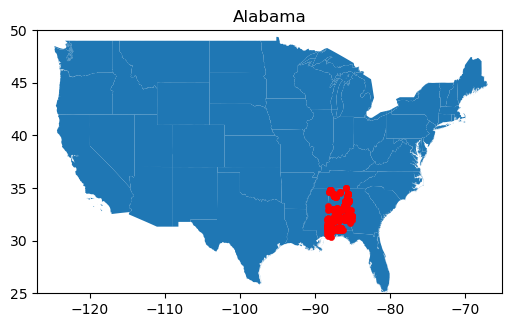

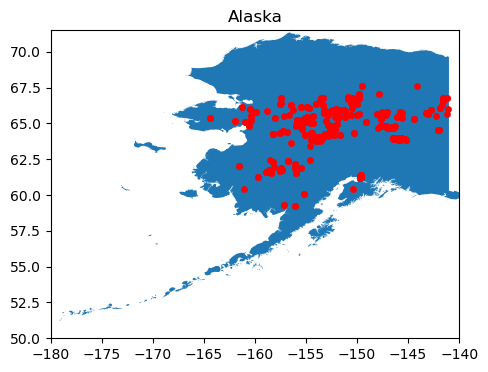

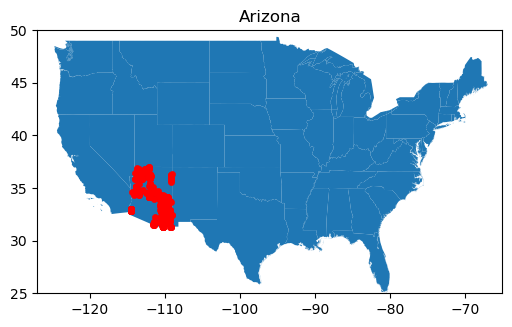

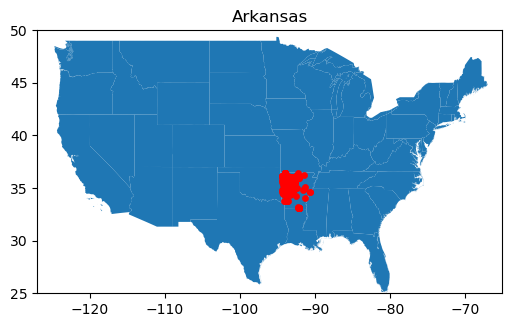

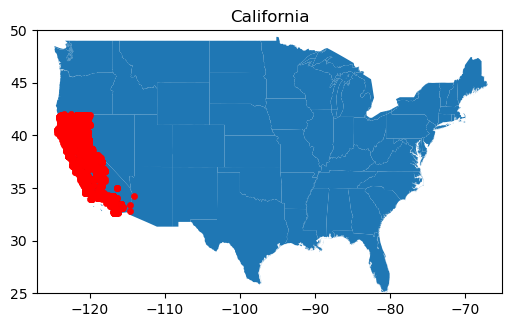

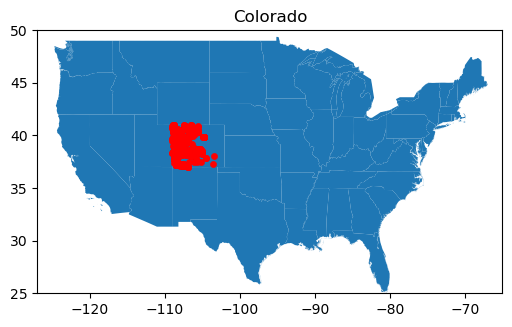

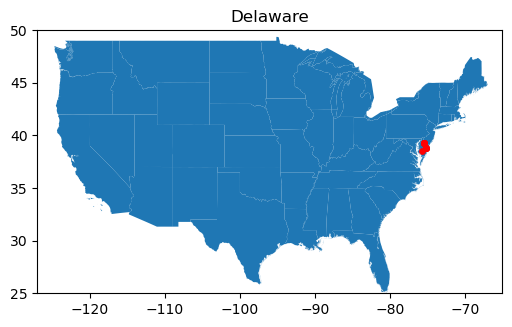

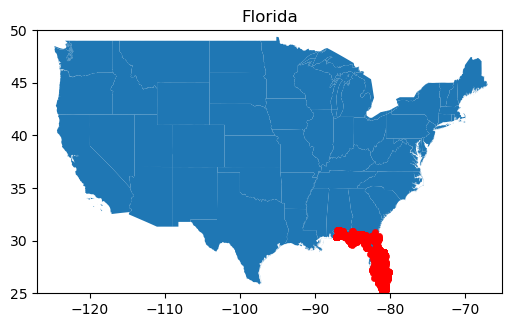

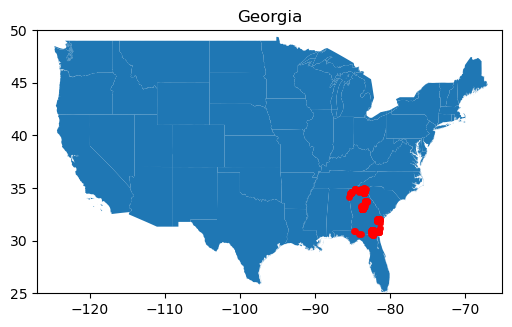

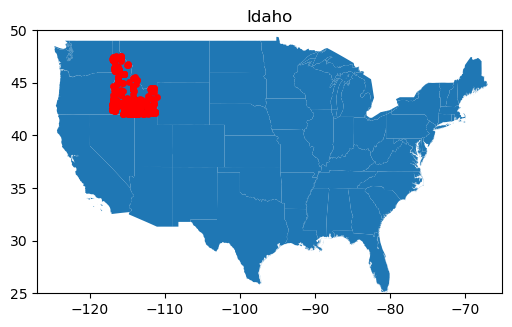

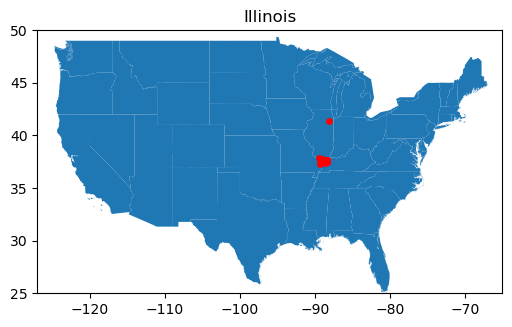

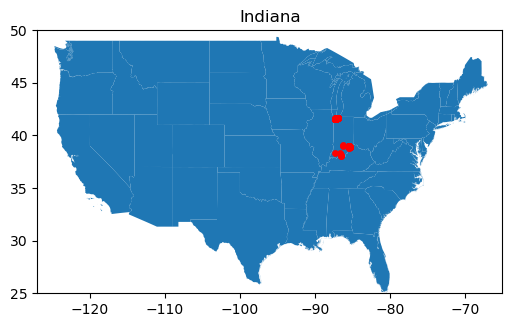

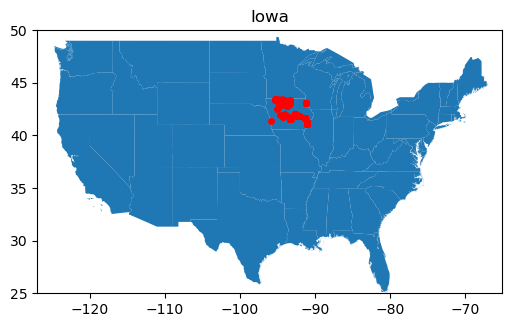

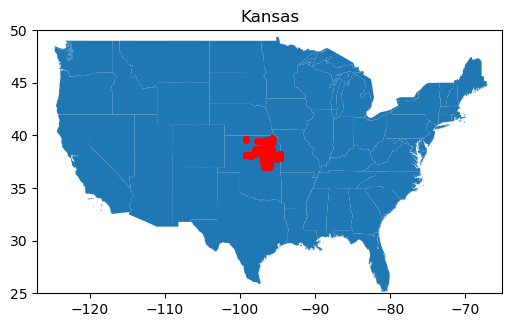

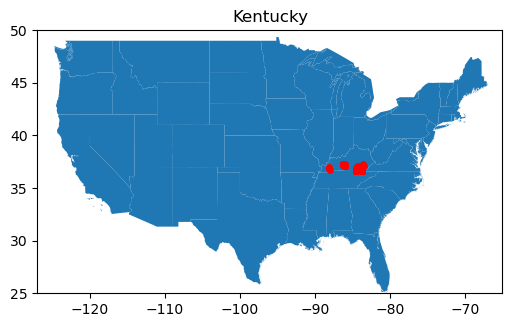

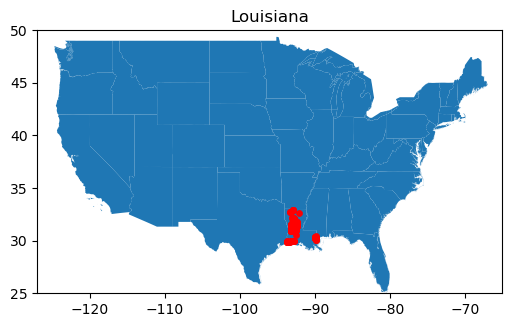

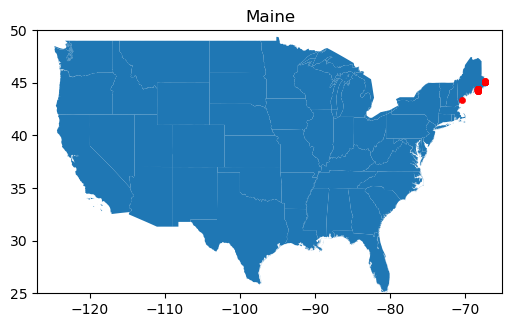

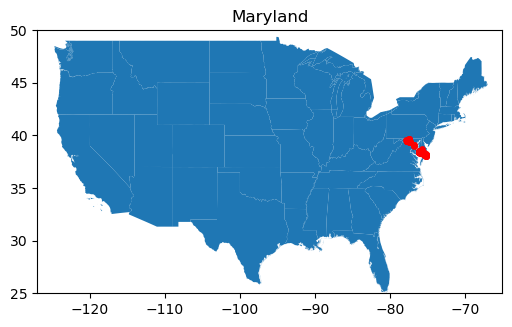

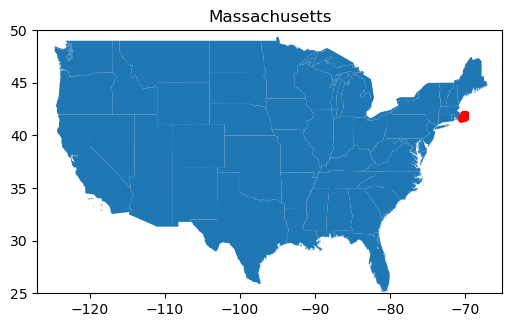

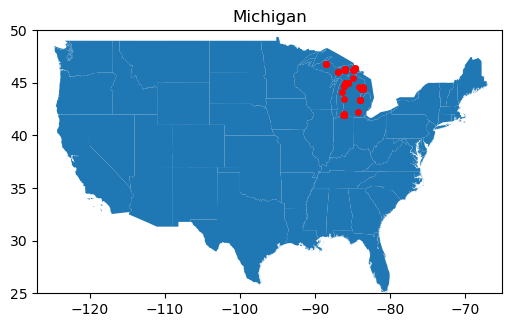

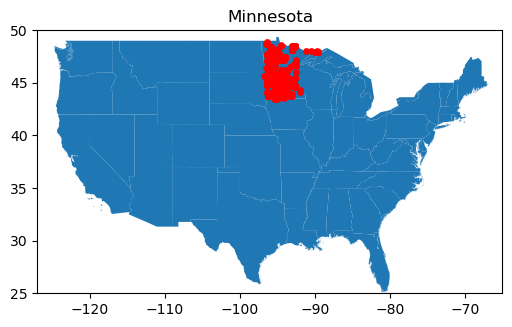

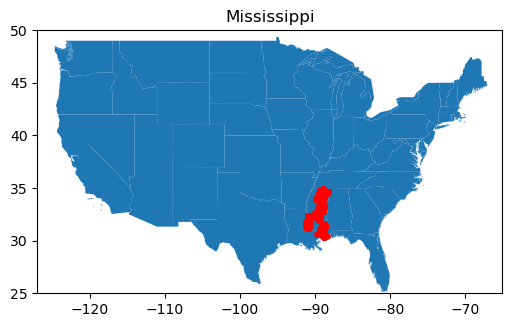

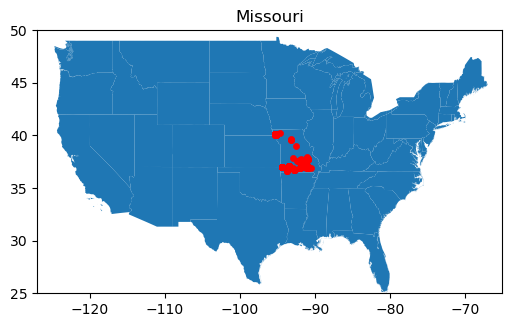

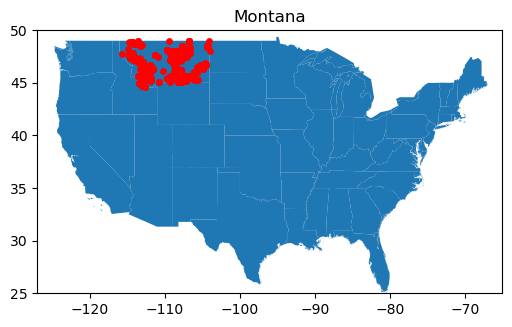

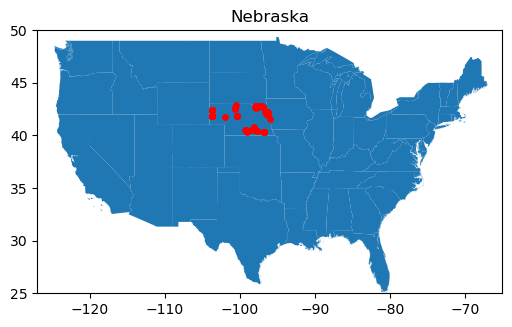

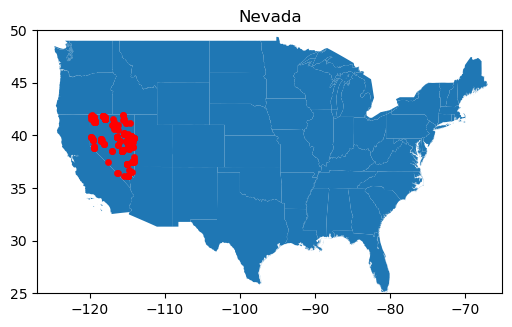

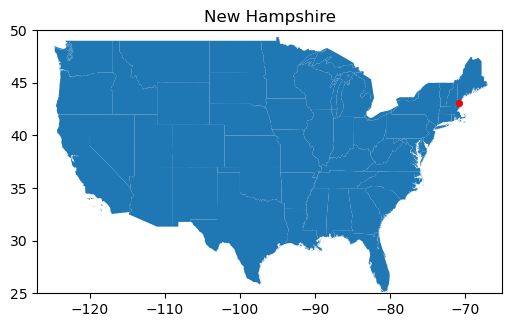

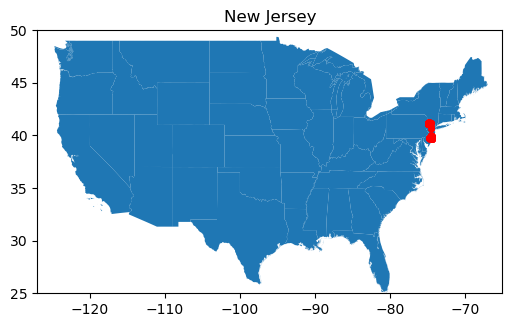

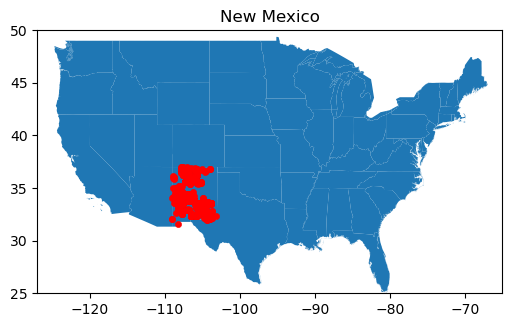

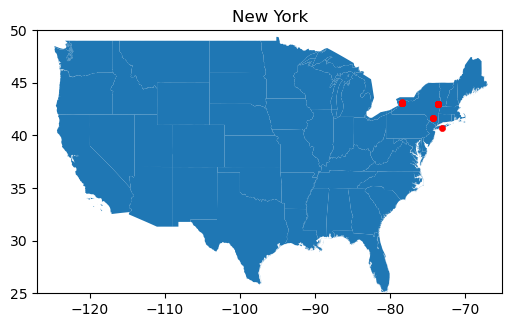

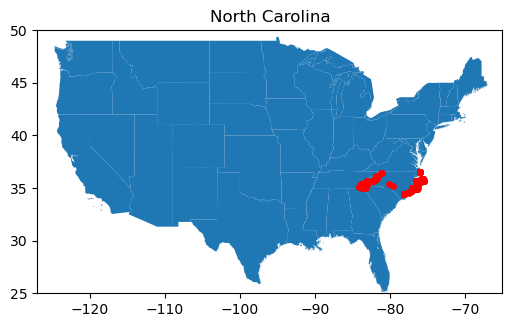

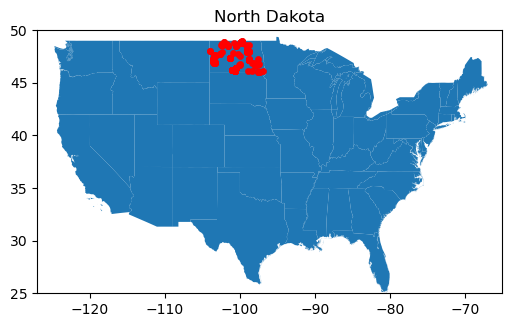

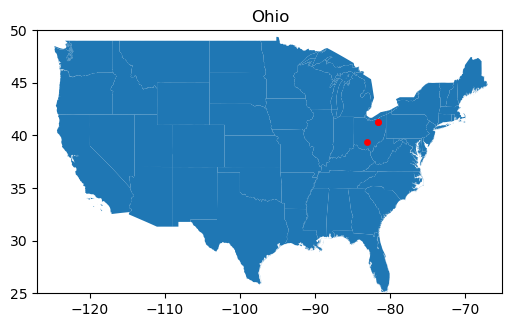

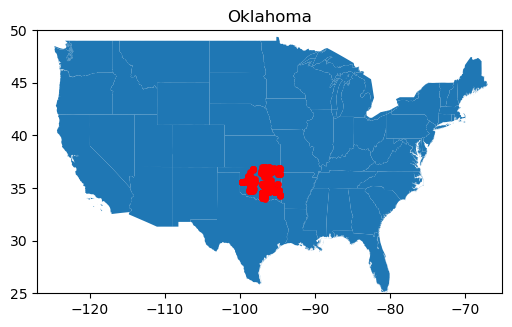

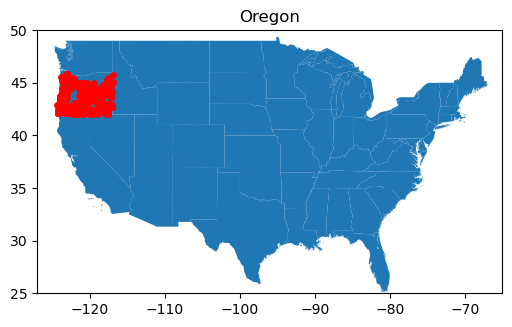

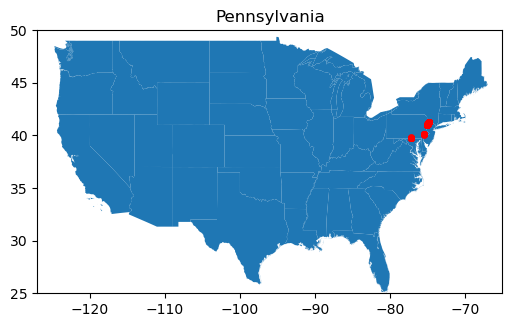

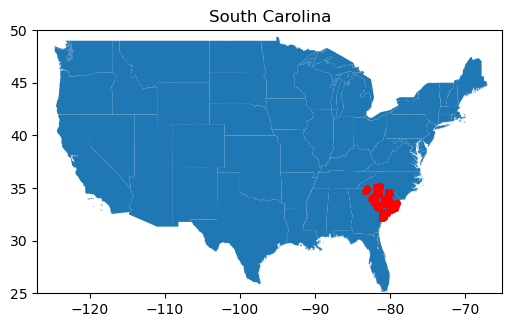

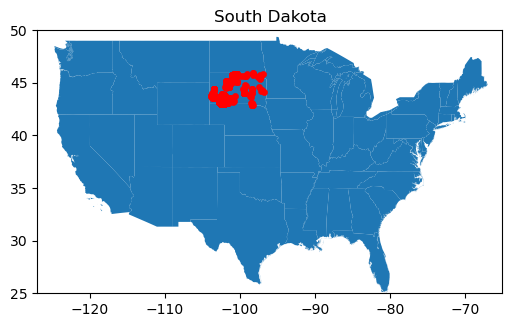

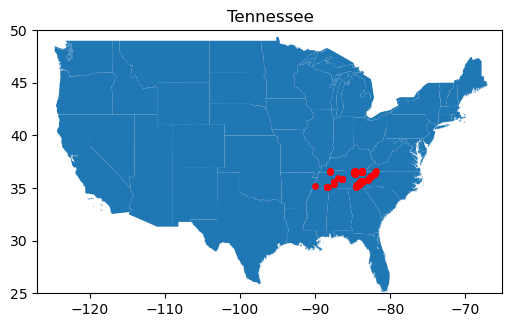

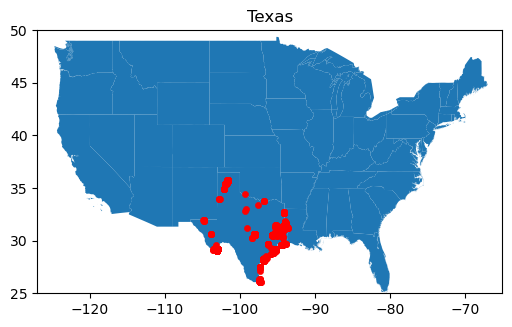

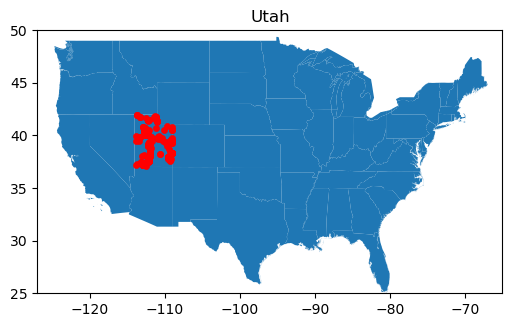

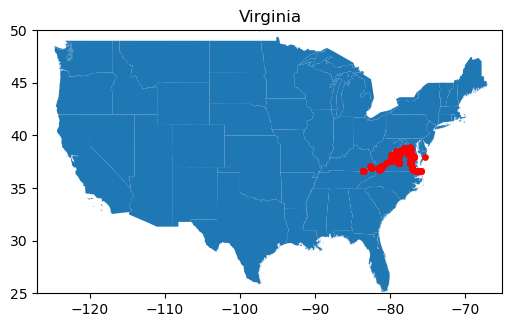

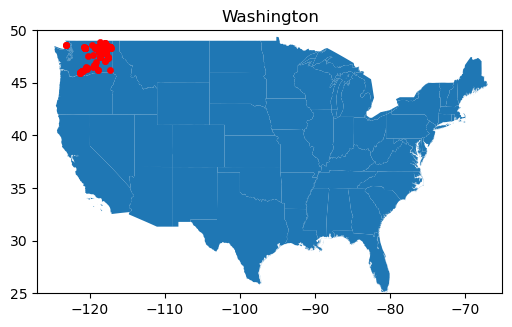

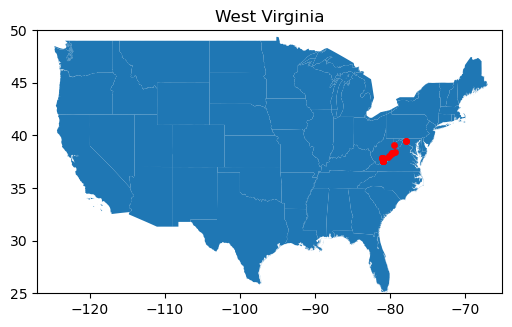

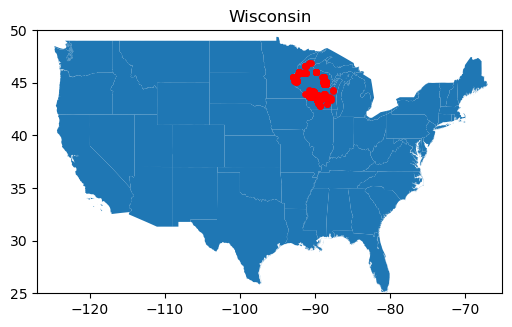

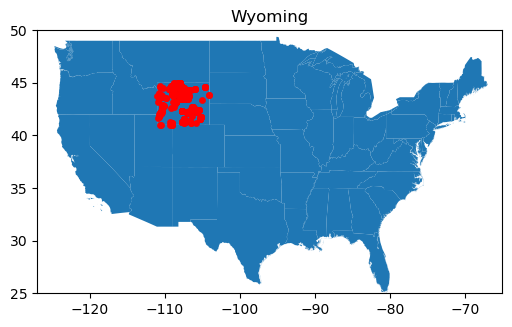

In [58]:
# import matplotlib.pyplot as plt

states = np.unique(df['State/Province'])
for state in states:
    fig, ax = plt.subplots(figsize=(6,4))
    
    USA_shp.plot(ax=ax,facecolor=None)
    
    state_df = df[df['State/Province']==state]
    lat = state_df['Latitude']
    lon = state_df['Longitude']

    # Color code by day of year
    ax.scatter(lon,lat,s=20,marker='o',color='red',linewidth=0.4)
    ax.set_title(state)

    if state == 'Alaska':
        # Alaska
        ax.set_xlim([-180,-140])
        ax.set_ylim([50,71.5])
    else:
        # CONUS
        ax.set_xlim([-127,-65])
        ax.set_ylim([25,50])

#### Get rid of duplicates in USGS vs MTBS data
* USGS dataset includes MTBS data up til 2020

In [198]:
MTBS_df = gpd.read_file('Raw_Rx/USA/MTBS/mtbs_perimeter_data/mtbs_perims_DD.shp')
MTBS_df = MTBS_df.loc[MTBS_df['Incid_Type']=='Prescribed Fire']
MTBS_df.dropna(subset='Ig_Date',inplace=True)
MTBS_df = MTBS_df.to_crs('EPSG:4326')

USGS_MTBS = USGS_raw.loc[USGS_raw['Data_Sourc']=='Comb_National_MTBS']
# Finds all points in MTBS data that fall within a USGS burn polygon on the same date (YMD)
dup_idxs = []
# Iterate through all MTBS dates
MTBS_df['Ig_Date'] = pd.to_datetime(MTBS_df['Ig_Date'])
for i in np.unique(pd.DatetimeIndex(MTBS_df['Ig_Date'])):
    
    # Extract all burns in MTBS and USGS datasets ocurring on the same date
    MTBS_pts = MTBS_df[MTBS_df['Ig_Date']==i]
    USGS_pol = USGS_raw[pd.DatetimeIndex(USGS_raw['Rx_Start_D'])==i]
    
    # Returns all datapoints in MTBS data that fall within a USGS perimeter on the same burn date
    join = gpd.sjoin(MTBS_pts,USGS_pol)
    
    # If no MTBS datapoints fall within a USGS perimeter on same burn date, join will be empty
    if len(join)>0:
        dup_idxs.append(join.index.values)
        
MTBS_dup_idxs = np.concatenate(dup_idxs).flatten()
MTBS_df.drop(MTBS_dup_idxs,inplace=True)

#### Get rid of duplicates in USGS vs NFPORS data

In [190]:
NFPORS_df = pd.read_excel('Rx_Reference_Data_20240216/USA_NFPORS_Rx.xlsx')

NFPORS_df['Date'] = pd.DatetimeIndex(NFPORS_df['Year'].astype(str)+'-'+NFPORS_df['Month'].astype(str)+'-'+NFPORS_df['Day'].astype(str).values)

NFPORS_pts = gpd.GeoDataFrame({'geometry':[Point(xy) for xy in zip(NFPORS_df['Longitude'],NFPORS_df['Latitude'])]})
NFPORS_pts.crs = 'EPSG:4326'

NFPORS_USGS = USGS_raw[USGS_raw['Data_Sourc']=='Comb_National_NFPORS_Rx_Data_No_Piles']
NFPORS_df['Date'] = pd.to_datetime(NFPORS_df['Date'])

# Finds all points in NFPORS data that fall within a USGS burn polygon on the same date (YMD)
dup_idxs = []
# Iterate through all NFPORS dates

for i in np.unique(pd.DatetimeIndex(NFPORS_df['Date'])):
    
    # Extract all burns in NFPORS and USGS datasets ocurring on the same date
    date_pts = NFPORS_pts[(NFPORS_df['Date']==i).values]
    USGS_pol = USGS_raw[pd.DatetimeIndex(USGS_raw['Rx_Start_D'])==i]

    # Returns all datapoints in NFPORS/NFPORS data that fall within a USGS perimeter on the same burn date
    join = gpd.sjoin(date_pts,USGS_pol)
    
    # If no MTBS/NFPORS datapoints fall within a USGS perimeter on same burn date, join will be empty
    if len(join)>0:
        dup_idxs.append(join.index.values)
        
NFPORS_dup_idxs = np.concatenate(dup_idxs).flatten()
NFPORS_df.drop(NFPORS_dup_idxs,inplace=True)
NFPORS_df.to_csv('NFPORS_cleaned_duplicates.csv',index=False)

In [178]:
cols = ['ID','Latitude','Longitude','Year','Month','Day','Time','Burn Objective',
        'Country','State/Province','Agency/Organisation','Timestamp of Update','Link to Data Repository',
        'Citation','Area Burned (Ha)']
df = pd.DataFrame(columns=cols)

df['ID'] = MTBS_df['Event_ID']
df['Latitude'] = MTBS_df['geometry'].to_crs('+proj=cea').centroid.to_crs('EPSG:4326').y.values
df['Longitude'] = MTBS_df['geometry'].to_crs('+proj=cea').centroid.to_crs('EPSG:4326').x.values
df['Year'] = pd.to_datetime(MTBS_df['Ig_Date'].values).year
df['Month'] = pd.to_datetime(MTBS_df['Ig_Date'].values).month
df['Day'] = pd.to_datetime(MTBS_df['Ig_Date'].values).day
df['Burn Objective'] = np.nan
df['Country'] = 'United States'
df['State/Province'] = np.array([state_dict[i[0:2]] for i in MTBS_df['Event_ID']])
df['Agency/Organisation'] = 'U.S. Geological Survey;USDA Forest Service'
df['Timestamp of Update'] = pd.Timestamp.today().date()
df['Data Repository'] = 'https://www.mtbs.gov/direct-download'
df['Citation'] = 'U.S. Geological Survey, USDA Forest Service, and Nelson, K., 2021, Monitoring Trends in Burn Severity (ver. 10.0, October 2024): U.S. Geological Survey data release, https://doi.org/10.5066/P9IED7RZ'
df['Area Burned (Ha)'] = MTBS_df['BurnBndAc'].values*0.404686

# df['Raw data filename(s)'] = file_name.split('/')[-1]

# Check if any dates are missing
np.isnan(df['Year'].values).any()
np.isnan(df['Month'].values).any()
np.isnan(df['Day'].values).any()

df.to_csv('MTBS_cleaned_duplicates.csv',index=False)

# Canada
* Metadata link [here](https://cwfis.cfs.nrcan.gc.ca/downloads/nfdb/fire_pnt/current_version/NFDB_point_shapefile_metadata.pdf)

## NFDB

In [1]:
import numpy as np
import pandas as pd

import geopandas as gpd
import fiona

In [2]:
file_name = 'Raw_Rx/Canada/NFDB/NFDB_filter.shp'
Rx_df = gpd.read_file(file_name)
Rx_df.to_crs('EPSG:4326',inplace=True)
Rx_df.dropna(subset='REP_DATE',inplace=True)

In [3]:
SRC_AGENCY = {'BC':'British Columbia','AB':'Alberta','SK':'Saskatchewan','MB':'Manitoba','ON':'Ontario','QC':'Quebec',
              'NS':'Nova Scotia','NB':'New Brunswick','NL':'Newfoundland & Labrador','YT':'Yukon','NT':'Northwest Territories',
              'PC-BA':'Banff (National Park)','PC-CB':'Cape Breton (National Park)','PC-EI':'Elk Island (National Park)',
              'PC-FO':'Forillon (National Park)','PC-GI':'Grosse-ile (National Park)','PC-GL':'Glacier (National Park)',
              'PC-GM':'Gros Morne (National Park)','PC-GR':'Grasslands (National Park)','PC-JA':'Jasper (National Park)',
              'PC-KE':'Kejimkujik (National Park)','PC-KO':'Kootenay (National Park)','PC-LM':'La Mauricie (National Park)',
              'PC-LO':'Louisbourg (National Park)','PC-PA':'Prince Albert (National Park)','PC-PP':'Point Pelee (National Park)',
              'PC-PU':'Pukaskwa (National Park)','PC-RE':'Mount Revelstoke (National Park)','PC-RM':'Riding Mountain (National Park)',
              'PC-RO':'Rocky Mountain House (National Park)','PC-SL':'St. Lawrence Islands (National Park)','PC-TI':'Thousand Islands (National Park)',
              'PC-TN':'Terra Nova (National Park)','PC-WL':'Waterton Lakes (National Park)','PC-YO':'Yoho (National Park)'}

In [5]:
Rx_lon = Rx_df['geometry'].to_crs('+proj=cea').centroid.to_crs('EPSG:4326').x.values
Rx_lat = Rx_df['geometry'].to_crs('+proj=cea').centroid.to_crs('EPSG:4326').y.values

Rx_date = Rx_df['REP_DATE']

In [6]:
# Assign data to DataFrame
cols = ['Raw data filename(s)','ID','Latitude','Longitude','Year','Month','Day','Time','Fire Type',
        'Country','State/Province','Agency / Organisation','Timestamp of Update','Link to Data Repository',
        'Citation','Area Burned','Area Burned Units']
df = pd.DataFrame(columns=cols)

df['ID'] = Rx_df['FIRE_ID'].values
df['Latitude'] = Rx_lat
df['Longitude'] = Rx_lon
df['Year'] = pd.to_datetime(Rx_df['REP_DATE'].values).year
df['Month'] = pd.to_datetime(Rx_df['REP_DATE'].values).month
df['Day'] = pd.to_datetime(Rx_df['REP_DATE'].values).day
df['Fire Type'] = 'Prescribed Fire'
df['Country'] = 'Canada'
df['State/Province'] = np.array([SRC_AGENCY[i] for i in Rx_df['SRC_AGENCY']])
df['Agency / Organisation'] = 'Natural Resources Canada'
df['Timestamp of Update'] = pd.Timestamp.today().date()
df['Link to Data Repository'] = 'https://cwfis.cfs.nrcan.gc.ca/datamart/metadata/nfdbpnt'
df['Citation'] = 'Canadian Forest Service. Canadian National Fire Database – Agency Fire Data. Natural Resources Canada, Canadian Forest Service, Northern Forestry Centre, Edmonton, Alberta 2022'
df['Area Burned'] = Rx_df['SIZE_HA'].values
df['Area Burned Units'] = 'Ha'

df['Raw data filename(s)'] = file_name.split('/')[-1]

# Check if any dates are missing
if np.isnan(df['Year'].values).any() or np.isnan(df['Month'].values).any() or np.isnan(df['Day'].values).any():
    print('Recheck dates, there are NaN values.')

df.to_csv('Process_Rx/Canada/NFDB.csv')

# Portugal
* Metadata link [here](https://geocatalogo.icnf.pt/metadados/area_ardida.html)

## 2021

In [141]:
file_name = 'Raw_Rx/Portugal/ICNF_AreaPercorridaFogo_31122021.shp'
fire_df = gpd.read_file(file_name)
Rx_df = fire_df[~(fire_df['LEGENDA']=='Incêndio rural')].to_crs('EPSG:4326')

In [142]:
LEGENDA = {'Fogo controlado':'Controlled Fire','Fogo controlado MARQ':'Controlled Fire for Range Management (MARQ Shepherd Program)',
          'Queimadas':'Prescribed burn without permit','Queimadas MARQ':'Prescribed burn (MARQ Shepherd Program)',
          'Queimadas-SemRegisto':'Unauthorized pastoral burn'}

In [143]:
# Assign data to DataFrame
cols = ['Raw data filename(s)','ID','Latitude','Longitude','Year','Month','Day','Time','Fire Type',
        'Country','State/Province','Agency / Organisation','Timestamp of Update','Link to Data Repository',
        'Citation','Area Burned','Area Burned Units']
df = pd.DataFrame(columns=cols)

df['ID'] = np.array(['ICNF'+str(i) for i in Rx_df.index])
df['Latitude'] = Rx_df['geometry'].to_crs('+proj=cea').centroid.to_crs('EPSG:4326').y.values
df['Longitude'] = Rx_df['geometry'].to_crs('+proj=cea').centroid.to_crs('EPSG:4326').x.values
df['Year'] = pd.to_datetime(Rx_df['Data_Exec'].values).year
df['Month'] = pd.to_datetime(Rx_df['Data_Exec'].values).month
df['Day'] = pd.to_datetime(Rx_df['Data_Exec'].values).day
df['Fire Type'] = np.array([LEGENDA[i] for i in Rx_df['LEGENDA']])
df['Country'] = 'Portugal'
df['State/Province'] = Rx_df['AUX_DistIn'].values
df['Agency / Organisation'] = 'Institute for Nature Conservation and Forests (INCF)'
df['Timestamp of Update'] = pd.Timestamp.today().date() 
df['Citation'] = 'Institute for Nature Conservation and Forests (ICNF). Record of prescribed burns on public land. Dataset accessed upon request [Paulo Fernandes, pers. comm.] (2023)'
df['Area Burned'] = Rx_df['Hectares'].values
df['Area Burned Units'] = 'Ha'

df['Raw data filename(s)'] = file_name.split('/')[-1]

# Check if any dates are missing
missing_dates = (np.isnan(df['Year'].values)+np.isnan(df['Month'].values)+np.isnan(df['Day'].values))
if missing_dates.any():
    df = df[~missing_dates]

df.to_csv('Process_Rx/Portugal/ICNF_2021.csv')

## 2022

In [144]:
file_name = 'Raw_Rx/Portugal/ICNF_AreaPercorridaFogo2022.shp'
fire_df = gpd.read_file(file_name)
Rx_df = fire_df[~(fire_df['LEGENDA']=='Incêndio rural')].to_crs('EPSG:4326')

In [145]:
LEGENDA = {'Fogo controlado':'Controlled Fire','Fogo controlado MARQ':'Controlled Fire for Range Management (MARQ Shepherd Program)',
          'Queimadas':'Prescribed burn without permit','Queimadas MARQ':'Prescribed burn (MARQ Shepherd Program)',
          'Queimadas-SemRegisto':'Unauthorized pastoral burn'}

In [149]:
fire_df[fire_df.columns[10:20]]

,AUX_ConcIn,AUX_FregIn,AUX_LimEst,AUX_Reacen,FonteDados,AUX_OBSERV,Ent_Fonte,Hectares,SHAPE_STAr,SHAPE_STLe
0,Cinfães,"UF Alhões, Bustelo, Gralheira e Ramires",None,None,Sentinel_2,None,ICNF,11.731069,NaN,NaN
1,Montalegre,UF Montalegre e Padroso,None,None,Sentinel_EFFIS,None,ICNF,16.373459,NaN,NaN
2,Montalegre,UF Montalegre e Padroso,None,None,Sentinel_EFFIS,None,ICNF,35.798682,NaN,NaN
3,Montalegre,UF Montalegre e Padroso,None,None,Sentinel_EFFIS,None,ICNF,11.315285,NaN,NaN
4,Montalegre,UF Montalegre e Padroso,None,None,Sentinel_EFFIS,None,ICNF,3.067053,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...
692,Lousada,UF Lustosa e Barrosas (Santo Estêvão),None,None,PQQ,None,ICNF,1.748935,NaN,NaN
693,Felgueiras,Idães,None,None,PQQ,None,ICNF,1.832092,NaN,NaN
694,Seia,UF Vide e Cabeça,None,None,Sentinel_EFFIS,None,ICNF,8.271381,NaN,NaN
695,Seia,UF Vide e Cabeça,None,None,Sentinel_EFFIS,None,ICNF,5.542738,NaN,NaN


In [146]:
# Assign data to DataFrame
cols = ['Raw data filename(s)','ID','Latitude','Longitude','Year','Month','Day','Time','Fire Type',
        'Country','State/Province','Agency / Organisation','Timestamp of Update','Link to Data Repository',
        'Citation','Area Burned','Area Burned Units']
df = pd.DataFrame(columns=cols)

df['ID'] = np.array(['ICNF'+str(i) for i in Rx_df.index])
df['Latitude'] = Rx_df['geometry'].to_crs('+proj=cea').centroid.to_crs('EPSG:4326').y.values
df['Longitude'] = Rx_df['geometry'].to_crs('+proj=cea').centroid.to_crs('EPSG:4326').x.values
df['Year'] = pd.to_datetime(Rx_df['Data_Exec'].values).year
df['Month'] = pd.to_datetime(Rx_df['Data_Exec'].values).month
df['Day'] = pd.to_datetime(Rx_df['Data_Exec'].values).day
df['Fire Type'] = np.array([LEGENDA[i] for i in Rx_df['LEGENDA']])
df['Country'] = 'Portugal'
df['State/Province'] = Rx_df['AUX_DistIn'].values
df['Agency / Organisation'] = 'Institute for Nature Conservation and Forests (INCF)'
df['Timestamp of Update'] = pd.Timestamp.today().date() 
df['Citation'] = 'Institute for Nature Conservation and Forests (ICNF). Record of prescribed burns on public land. Dataset accessed upon request [Paulo Fernandes, pers. comm.] (2023)'
df['Area Burned'] = Rx_df['Hectares'].values
df['Area Burned Units'] = 'Ha'

df['Raw data filename(s)'] = file_name.split('/')[-1]

# Check if any dates are missing
missing_dates = (np.isnan(df['Year'].values)+np.isnan(df['Month'].values)+np.isnan(df['Day'].values))
if missing_dates.any():
    df = df[~missing_dates]

df.to_csv('Process_Rx/Portugal/ICNF_2022.csv')